In [144]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [145]:
import os
import glob
import pandas as pd

DATA_PATH = "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/raw"

csv_files = glob.glob(os.path.join(DATA_PATH, "*.csv"))

print("Total CSV files:", len(csv_files))

for file in csv_files:
    df = pd.read_csv(file, nrows=5)

    print("\nFile:", os.path.basename(file))
    print("Columns:", list(df.columns))
    print("Preview:")
    display(df.head(2))


Total CSV files: 9

File: olist_customers_dataset.csv
Columns: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
Preview:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP



File: olist_geolocation_dataset.csv
Columns: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']
Preview:


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP



File: olist_order_items_dataset.csv
Columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
Preview:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93


... (8 outputs left out)


File: olist_sellers_dataset.csv
Columns: ['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']
Preview:


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP



File: product_category_name_translation.csv
Columns: ['product_category_name', 'product_category_name_english']
Preview:


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories


In [146]:

import pandas as pd
import os

DATA_PATH = "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/raw"

#load all datasets
customers = pd.read_csv(f"{DATA_PATH}/olist_customers_dataset.csv")
geolocation = pd.read_csv(f"{DATA_PATH}/olist_geolocation_dataset.csv")
order_items = pd.read_csv(f"{DATA_PATH}/olist_order_items_dataset.csv")
payments = pd.read_csv(f"{DATA_PATH}/olist_order_payments_dataset.csv")
reviews = pd.read_csv(f"{DATA_PATH}/olist_order_reviews_dataset.csv")
orders = pd.read_csv(f"{DATA_PATH}/olist_orders_dataset.csv")
products = pd.read_csv(f"{DATA_PATH}/olist_products_dataset.csv")
sellers = pd.read_csv(f"{DATA_PATH}/olist_sellers_dataset.csv")
category_translation = pd.read_csv(f"{DATA_PATH}/product_category_name_translation.csv")

#store datasets in a dictionary
datasets = {
    "customers": customers,
    "geolocation": geolocation,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "orders": orders,
    "products": products,
    "sellers": sellers,
    "category_translation": category_translation
}

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [147]:
for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

customers: 99,441 rows × 5 columns
geolocation: 1,000,163 rows × 5 columns
order_items: 112,650 rows × 7 columns
payments: 103,886 rows × 5 columns
reviews: 99,224 rows × 7 columns
orders: 99,441 rows × 8 columns
products: 32,951 rows × 9 columns
sellers: 3,095 rows × 4 columns
category_translation: 71 rows × 2 columns


In [148]:
for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")

    print(df.info())


DATASET: CUSTOMERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB
None

DATASET: GEOLOCATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   

In [149]:
for name, df in datasets.items():
    print(f"\nDATASET: {name.upper()}")

    print("Missing values:")
    print(df.isnull().sum()[df.isnull().sum() > 0])

    print("Duplicate rows:", df.duplicated().sum())


DATASET: CUSTOMERS
Missing values:
Series([], dtype: int64)
Duplicate rows: 0

DATASET: GEOLOCATION
Missing values:
Series([], dtype: int64)
Duplicate rows: 261831

DATASET: ORDER_ITEMS
Missing values:
Series([], dtype: int64)
Duplicate rows: 0

DATASET: PAYMENTS
Missing values:
Series([], dtype: int64)
Duplicate rows: 0

DATASET: REVIEWS
Missing values:
review_comment_title      87656
review_comment_message    58247
dtype: int64
Duplicate rows: 0

DATASET: ORDERS
Missing values:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
Duplicate rows: 0

DATASET: PRODUCTS
Missing values:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
Duplicate rows: 0

DATASET: SELLERS
Missing value

In [150]:

data_dictionary = []

for name, df in datasets.items():
    for column in df.columns:
        data_dictionary.append({
            "Dataset": name,
            "Column": column,
            "Data Type": str(df[column].dtype),
            "Missing Values": df[column].isnull().sum(),
            "Unique Values": df[column].nunique()
        })

data_dictionary_df = pd.DataFrame(data_dictionary)

display(data_dictionary_df)

# Save preliminary data dictionary
data_dictionary_df.to_csv("/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/reports/preliminary_data_dictionary.csv",index=False)


,Dataset,Column,Data Type,Missing Values,Unique Values
0,customers,customer_id,object,0,99441
1,customers,customer_unique_id,object,0,96096
2,customers,customer_zip_code_prefix,int64,0,14994
3,customers,customer_city,object,0,4119
4,customers,customer_state,object,0,27
5,geolocation,geolocation_zip_code_prefix,int64,0,19015
6,geolocation,geolocation_lat,float64,0,717360
7,geolocation,geolocation_lng,float64,0,717613
8,geolocation,geolocation_city,object,0,8011
9,geolocation,geolocation_state,object,0,27


**Which dataset has the most missing information?**

**Which dataset has the highest percentage of missing values?**

**Are there duplicate records?**

**Which datasets appear relatively clean?**

In [151]:

quality_report = []

for name, df in datasets.items():

    quality_report.append({
        "Dataset": name,
        "Total Rows": len(df),
        "Total Columns": len(df.columns),
        "Missing Cells": df.isnull().sum().sum(),
        "Missing Percentage": round(
            df.isnull().sum().sum() /
            (df.shape[0] * df.shape[1]) * 100, 2
        ),
        "Duplicate Rows": df.duplicated().sum()
    })

quality_df = pd.DataFrame(quality_report)

display(quality_df.sort_values(
    by="Missing Percentage",
    ascending=False
))


,Dataset,Total Rows,Total Columns,Missing Cells,Missing Percentage,Duplicate Rows
4,reviews,99224,7,145903,21.01,0
6,products,32951,9,2448,0.83,0
5,orders,99441,8,4908,0.62,0
0,customers,99441,5,0,0.00,0
1,geolocation,1000163,5,0,0.00,261831
3,payments,103886,5,0,0.00,0
2,order_items,112650,7,0,0.00,0
7,sellers,3095,4,0,0.00,0
8,category_translation,71,2,0,0.00,0


**Column Level Missing Value Analysis**

In [152]:
for name, df in datasets.items():

    missing = df.isnull().sum()

    missing = missing[missing > 0]

    if len(missing) > 0:

        print(f"\n{'='*50}")
        print(f"DATASET: {name.upper()}")
        print(f"{'='*50}")

        missing_report = pd.DataFrame({
            "Missing Count": missing,
            "Missing Percentage": (
                missing / len(df) * 100
            ).round(2)
        })

        display(missing_report)



DATASET: REVIEWS


,Missing Count,Missing Percentage
review_comment_title,87656,88.34
review_comment_message,58247,58.70



DATASET: ORDERS


,Missing Count,Missing Percentage
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98



DATASET: PRODUCTS


,Missing Count,Missing Percentage
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01


In [153]:
#counting missing timestamps by order status
timestamp_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

for column in timestamp_columns:

    print(f"\nMissing {column} by order status:")

    missing_orders = orders[
        orders[column].isnull()
    ]

    display(
        missing_orders["order_status"]
        .value_counts()
        .to_frame("Missing Orders")
    )



Missing order_approved_at by order status:


,Missing Orders
order_status,
canceled,141
delivered,14
created,5



Missing order_delivered_carrier_date by order status:


,Missing Orders
order_status,
unavailable,609
canceled,550
invoiced,314
processing,301
created,5
approved,2
delivered,2



Missing order_delivered_customer_date by order status:


,Missing Orders
order_status,
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2


In [154]:
#products missing category information
missing_category = products[
    products["product_category_name"].isnull()
]

print("Products missing category:",
      len(missing_category))

display(missing_category.head(10))


#products missing physical measurements
missing_dimensions = products[
    products["product_weight_g"].isnull() |
    products["product_length_cm"].isnull() |
    products["product_height_cm"].isnull() |
    products["product_width_cm"].isnull()
]

print("Products missing physical measurements:",
      len(missing_dimensions))

display(missing_dimensions)


Products missing category: 610


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


Products missing physical measurements: 2


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [155]:
#finding delivered orders with missing timestamps

delivered_anomalies = orders[
    (orders["order_status"] == "delivered") &
    (
        orders["order_approved_at"].isnull() |
        orders["order_delivered_carrier_date"].isnull() |
        orders["order_delivered_customer_date"].isnull()
    )
]

display(
    delivered_anomalies[
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
    ]
)

print("Total delivered orders with missing timestamps:",
      len(delivered_anomalies))

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN
5323,e04abd8149ef81b95221e88f6ed9ab6a,delivered,2017-02-18 14:40:00,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33
16567,8a9adc69528e1001fc68dd0aaebbb54a,delivered,2017-02-18 12:45:31,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06
19031,7013bcfc1c97fe719a7b5e05e61c12db,delivered,2017-02-18 13:29:47,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN
22663,5cf925b116421afa85ee25e99b4c34fb,delivered,2017-02-18 16:48:35,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47
23156,12a95a3c06dbaec84bcfb0e2da5d228a,delivered,2017-02-17 13:05:55,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19
26800,c1d4211b3dae76144deccd6c74144a88,delivered,2017-01-19 12:48:08,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01
38290,d69e5d356402adc8cf17e08b5033acfb,delivered,2017-02-19 01:28:47,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58
39334,d77031d6a3c8a52f019764e68f211c69,delivered,2017-02-18 11:04:19,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23


Total delivered orders with missing timestamps: 23


In [156]:
#geolocation duplicate investigation

geo = datasets["geolocation"]

print("Total rows:", len(geo))
print("Exact duplicate rows:", geo.duplicated().sum())
print("Unique rows:", len(geo.drop_duplicates()))

#displaying some exact duplicate records
geo_duplicates = geo[
    geo.duplicated(keep=False)
].sort_values(by="geolocation_zip_code_prefix")

display(geo_duplicates.head(20))

Total rows: 1000163
Exact duplicate rows: 261831
Unique rows: 738332


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
851,1001,-23.549825,-46.633970,sao paulo,SP
1062,1001,-23.550498,-46.634338,sao paulo,SP
1246,1001,-23.549292,-46.633559,sao paulo,SP
897,1001,-23.549292,-46.633559,sao paulo,SP
99,1001,-23.549292,-46.633559,sao paulo,SP
864,1001,-23.549825,-46.633970,sao paulo,SP
771,1001,-23.550498,-46.634338,sao paulo,SP
818,1001,-23.551337,-46.634027,sao paulo,SP
1384,1001,-23.549292,-46.633559,sao paulo,SP
429,1001,-23.550498,-46.634338,sao paulo,SP


In [157]:
#checking exact duplicate rows across all datasets

for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum():,} exact duplicate rows"
    )

customers: 0 exact duplicate rows
geolocation: 261,831 exact duplicate rows
order_items: 0 exact duplicate rows
payments: 0 exact duplicate rows
reviews: 0 exact duplicate rows
orders: 0 exact duplicate rows
products: 0 exact duplicate rows
sellers: 0 exact duplicate rows
category_translation: 0 exact duplicate rows


In [158]:
#creating a deduplicated copy of geolocation

geolocation_clean = datasets["geolocation"].drop_duplicates().copy()

print("Original rows:", len(datasets["geolocation"]))
print("Rows after deduplication:", len(geolocation_clean))
print("Remaining exact duplicates:", geolocation_clean.duplicated().sum())

#chhecking repeated postal code prefixes
print(
    "Unique postal code prefixes:",
    geolocation_clean["geolocation_zip_code_prefix"].nunique()
)

Original rows: 1000163
Rows after deduplication: 738332
Remaining exact duplicates: 0
Unique postal code prefixes: 19015


In [159]:
#checking expected primary keys

primary_keys = {
    "customers": ["customer_id"],
    "orders": ["order_id"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "order_items": ["order_id", "order_item_id"],
    "payments": ["order_id", "payment_sequential"],
    "reviews": ["review_id"],
    "category_translation": ["product_category_name"]
}

for name, columns in primary_keys.items():
    df = datasets[name]

    print(f"\n{name.upper()}")

    for column in columns:
        print(
            f"{column}: "
            f"Duplicates = {df[column].duplicated().sum()}, "
            f"Missing = {df[column].isnull().sum()}"
        )


CUSTOMERS
customer_id: Duplicates = 0, Missing = 0

ORDERS
order_id: Duplicates = 0, Missing = 0

PRODUCTS
product_id: Duplicates = 0, Missing = 0

SELLERS
seller_id: Duplicates = 0, Missing = 0

ORDER_ITEMS
order_id: Duplicates = 13984, Missing = 0
order_item_id: Duplicates = 112629, Missing = 0

PAYMENTS
order_id: Duplicates = 4446, Missing = 0
payment_sequential: Duplicates = 103857, Missing = 0

REVIEWS
review_id: Duplicates = 814, Missing = 0

CATEGORY_TRANSLATION
product_category_name: Duplicates = 0, Missing = 0


In [160]:
#validation composite primary keys

print("ORDER ITEMS")
print(
    "Duplicate composite keys:",
    datasets["order_items"].duplicated(
        subset=["order_id", "order_item_id"]
    ).sum()
)

print("\nPAYMENTS")
print(
    "Duplicate composite keys:",
    datasets["payments"].duplicated(
        subset=["order_id", "payment_sequential"]
    ).sum()
)

#investigation duplicate review ids

print("\nREVIEWS")

duplicate_reviews = datasets["reviews"][
    datasets["reviews"].duplicated(
        subset=["review_id"],
        keep=False
    )
].sort_values("review_id")

print("Rows with duplicated review IDs:", len(duplicate_reviews))

display(duplicate_reviews.head(20))

ORDER ITEMS
Duplicate composite keys: 0

PAYMENTS
Duplicate composite keys: 0

REVIEWS
Rows with duplicated review IDs: 1603


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [161]:
#investigating duplicate review ids

reviews = datasets["reviews"]

#counting how many times each review id occurs
review_id_counts = (
    reviews["review_id"]
    .value_counts()
)

print("Review IDs appearing more than once:",
      (review_id_counts > 1).sum())

#checkin whether duplicate IDs have different order ids
duplicate_review_records = reviews[
    reviews["review_id"].isin(
        review_id_counts[review_id_counts > 1].index
    )
].sort_values("review_id")

display(duplicate_review_records.head(20))

#checkin exact duplicate rows
print(
    "Exact duplicate review rows:",
    reviews.duplicated().sum()
)

#checkin missing order IDs among duplicate review records
print(
    "Missing order IDs in duplicate review records:",
    duplicate_review_records["order_id"].isnull().sum()
)

Review IDs appearing more than once: 789


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


Exact duplicate review rows: 0
Missing order IDs in duplicate review records: 0


In [162]:
#analyzing repeated review ids

review_id_analysis = (
    duplicate_review_records
    .groupby("review_id")
    .agg(
        Number_of_Rows=("review_id", "size"),
        Unique_Orders=("order_id", "nunique"),
        Unique_Scores=("review_score", "nunique"),
        Unique_Comments=("review_comment_message", "nunique")
    )
    .reset_index()
)

display(review_id_analysis.head(20))

print(
    "Repeated review IDs linked to multiple orders:",
    (review_id_analysis["Unique_Orders"] > 1).sum()
)

print(
    "Repeated review IDs with different scores:",
    (review_id_analysis["Unique_Scores"] > 1).sum()
)

,review_id,Number_of_Rows,Unique_Orders,Unique_Scores,Unique_Comments
0,00130cbe1f9d422698c812ed8ded1919,2,2,1,1
1,0115633a9c298b6a98bcbe4eee75345f,2,2,1,0
2,0174caf0ee5964646040cd94e15ac95e,2,2,1,1
3,017808d29fd1f942d97e50184dfb4c13,2,2,1,0
4,0254bd905dc677a6078990aad3331a36,2,2,1,1
5,0288d42bef3dfe36930740c9588a570f,2,2,1,0
6,02aa7f5f75e964e3c7efa59a1f515281,2,2,1,0
7,034528cb00b6bc981847acafbdf2ae0b,2,2,1,0
8,03a6a25db577d0689440933055111897,2,2,1,1
9,0467560f511c516ddaa54a60edb0c291,2,2,1,0


Repeated review IDs linked to multiple orders: 789
Repeated review IDs with different scores: 0


In [163]:
#testing whether review_id + order_id uniquely identifies a review record

print(
    "Duplicate review_id + order_id combinations:",
    reviews.duplicated(
        subset=["review_id", "order_id"]
    ).sum()
)

#inspecting all records for one repeated review id
sample_review_id = review_id_counts[
    review_id_counts > 1
].index[0]

print("\nExample of a repeated review ID:")
display(
    reviews[reviews["review_id"] == sample_review_id]
)

Duplicate review_id + order_id combinations: 0

Example of a repeated review ID:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
58393,4548534449b1f572e357211b90724f1b,cfdfd7862e532c4ec1ed1c6a1b56d320,1,NaN,quero devolver o produto comprei um veio outro...,2018-08-18 00:00:00,2018-08-19 00:39:54
92768,4548534449b1f572e357211b90724f1b,a2ac6dad85cf8af5b0afb510a240fe8c,1,NaN,quero devolver o produto comprei um veio outro...,2018-08-18 00:00:00,2018-08-19 00:39:54
95402,4548534449b1f572e357211b90724f1b,73a8ed1078e1d475d2b1fb7216a52e1a,1,NaN,quero devolver o produto comprei um veio outro...,2018-08-18 00:00:00,2018-08-19 00:39:54


In [164]:
#foreign key validation

relationships = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "seller_id", "sellers", "seller_id"),
    ("payments", "order_id", "orders", "order_id"),
    ("reviews", "order_id", "orders", "order_id"),
]

for child_table, fk, parent_table, pk in relationships:

    child = datasets[child_table]
    parent = datasets[parent_table]

    invalid = child[
        child[fk].notna() &
        ~child[fk].isin(parent[pk])
    ]

    print(
        f"{child_table}.{fk} -> {parent_table}.{pk}: "
        f"{len(invalid)} invalid references"
    )

orders.customer_id -> customers.customer_id: 0 invalid references
order_items.order_id -> orders.order_id: 0 invalid references
order_items.product_id -> products.product_id: 0 invalid references
order_items.seller_id -> sellers.seller_id: 0 invalid references
payments.order_id -> orders.order_id: 0 invalid references
reviews.order_id -> orders.order_id: 0 invalid references


**Handling missing values**

In [165]:
#creating working copies for data cleaning

processed = {}

for name, df in datasets.items():
    processed[name] = df.copy()

#replacing geolocation with its deduplicated copy
processed["geolocation"] = geolocation_clean.copy()

print("Working copies created:", len(processed))

for name, df in processed.items():
    print(f"{name}: {df.shape}")

Working copies created: 9
customers: (99441, 5)
geolocation: (738332, 5)
order_items: (112650, 7)
payments: (103886, 5)
reviews: (99224, 7)
orders: (99441, 8)
products: (32951, 9)
sellers: (3095, 4)
category_translation: (71, 2)


**Handling missing values in reviews**

In [166]:
#checking missing values in processed reviews

reviews_clean = processed["reviews"]

print("Before treatment:")
display(reviews_clean.isnull().sum())

#preserving missing comments as null
#no imputation or row deletion required

print("\nAfter treatment:")
display(reviews_clean.isnull().sum())

print("\nTotal review records:", len(reviews_clean))

Before treatment:


,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0



After treatment:


,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0



Total review records: 99224


**Handling missing values in orders**

In [167]:
#checking missing values in processed orders

orders_clean = processed["orders"]

print("Before treatment:")
display(orders_clean.isnull().sum())

#preserving missing timestamps as null
#no imputation or row deletion required

print("\nAfter treatment:")
display(orders_clean.isnull().sum())

print("\nTotal order records:", len(orders_clean))

Before treatment:


,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0



After treatment:


,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0



Total order records: 99441


**Handling missing values in products**

In [168]:
products_clean = processed["products"]

print("Before treatment:")
display(products_clean.isnull().sum())

print("\nAfter treatment:")
display(products_clean.isnull().sum())

print("\nTotal product records:", len(products_clean))

Before treatment:


,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2



After treatment:


,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2



Total product records: 32951


**Investigating missing product categories**

In [169]:
#inspecting category translation table

display(processed["category_translation"].head(10))

print(
    "Unique original categories:",
    processed["category_translation"][
        "product_category_name"
    ].nunique()
)

print(
    "Unique English categories:",
    processed["category_translation"][
        "product_category_name_english"
    ].nunique()
)

#checking whether any product categories are absent
#from the translation table

product_categories = set(
    products_clean["product_category_name"].dropna()
)

translated_categories = set(
    processed["category_translation"][
        "product_category_name"
    ].dropna()
)

untranslated = product_categories - translated_categories

print("Categories without translation:", len(untranslated))
print("Examples:", list(untranslated)[:10])

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor
5,esporte_lazer,sports_leisure
6,perfumaria,perfumery
7,utilidades_domesticas,housewares
8,telefonia,telephony
9,relogios_presentes,watches_gifts


Unique original categories: 71
Unique English categories: 71
Categories without translation: 2
Examples: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


In [170]:
#creating a translation dictionary
category_translation = (
    processed["category_translation"]
    .set_index("product_category_name")
    ["product_category_name_english"]
    .to_dict()
)

#add translations for the two missing categories
category_translation.update({
    "portateis_cozinha_e_preparadores_de_alimentos":
        "portable_kitchen_and_food_processors",
    "pc_gamer": "gaming_pc"
})

#creating a new English category column
processed["products"]["product_category_name_english"] = (
    processed["products"]["product_category_name"]
    .map(category_translation)
)

#verifying the results
print("Original missing categories:",
      processed["products"]["product_category_name"].isna().sum())

print("Missing English categories:",
      processed["products"]["product_category_name_english"].isna().sum())

print("\nSample results:")
display(
    processed["products"][
        ["product_category_name",
         "product_category_name_english"]
    ].head(15)
)

Original missing categories: 610
Missing English categories: 610

Sample results:


,product_category_name,product_category_name_english
0,perfumaria,perfumery
1,artes,art
2,esporte_lazer,sports_leisure
3,bebes,baby
4,utilidades_domesticas,housewares
5,instrumentos_musicais,musical_instruments
6,cool_stuff,cool_stuff
7,moveis_decoracao,furniture_decor
8,eletrodomesticos,home_appliances
9,brinquedos,toys


**Reviewing missing value treatment across all nine datasets**

In [171]:
#final missing value summary
missing_summary = []

for name, df in processed.items():
    missing_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Missing Cells": df.isnull().sum().sum(),
        "Columns with Missing Values":
            df.columns[df.isnull().any()].tolist()
    })

missing_summary_df = pd.DataFrame(missing_summary)

display(missing_summary_df)

,Dataset,Rows,Missing Cells,Columns with Missing Values
0,customers,99441,0,[]
1,geolocation,738332,0,[]
2,order_items,112650,0,[]
3,payments,103886,0,[]
4,reviews,99224,145903,"[review_comment_title, review_comment_message]"
5,orders,99441,4908,"[order_approved_at, order_delivered_carrier_da..."
6,products,32951,3058,"[product_category_name, product_name_lenght, p..."
7,sellers,3095,0,[]
8,category_translation,71,0,[]


In [172]:
missing_decisions = pd.DataFrame([
    ["reviews", "review_comment_title",
     87656, "Preserved as NULL",
     "Review titles are optional."],

    ["reviews", "review_comment_message",
     58247, "Preserved as NULL",
     "Customers can submit ratings without written comments."],

    ["orders", "order_approved_at",
     160, "Preserved as NULL",
     "Approval timestamps are unavailable for some orders."],

    ["orders", "order_delivered_carrier_date",
     1783, "Preserved as NULL",
     "Carrier handover timestamps are unavailable for some orders."],

    ["orders", "order_delivered_customer_date",
     2965, "Preserved as NULL",
     "Delivery timestamps are unavailable for some orders."],

    ["products", "product_category_name",
     610, "Preserved as NULL",
     "Original product category is unknown."],

    ["products", "product_name_lenght",
     610, "Preserved as NULL",
     "Original product name length is unavailable."],

    ["products", "product_description_lenght",
     610, "Preserved as NULL",
     "Original product description length is unavailable."],

    ["products", "product_photos_qty",
     610, "Preserved as NULL",
     "Product photo quantity is unavailable."],

    ["products", "Physical measurements",
     2, "Preserved as NULL",
     "Weight and dimensions are unavailable for two products."],

    ["products", "product_category_name_english",
     610, "Preserved as NULL",
     "English translation is unavailable because the original category is missing."]
], columns=[
    "Dataset", "Column", "Missing_Count",
    "Treatment", "Reason"
])

missing_decisions.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/reports/missing_value_decisions.csv",
    index=False
)

print("Missing-value decisions saved successfully.")
display(missing_decisions)

Missing-value decisions saved successfully.


,Dataset,Column,Missing_Count,Treatment,Reason
0,reviews,review_comment_title,87656,Preserved as NULL,Review titles are optional.
1,reviews,review_comment_message,58247,Preserved as NULL,Customers can submit ratings without written c...
2,orders,order_approved_at,160,Preserved as NULL,Approval timestamps are unavailable for some o...
3,orders,order_delivered_carrier_date,1783,Preserved as NULL,Carrier handover timestamps are unavailable fo...
4,orders,order_delivered_customer_date,2965,Preserved as NULL,Delivery timestamps are unavailable for some o...
5,products,product_category_name,610,Preserved as NULL,Original product category is unknown.
6,products,product_name_lenght,610,Preserved as NULL,Original product name length is unavailable.
7,products,product_description_lenght,610,Preserved as NULL,Original product description length is unavail...
8,products,product_photos_qty,610,Preserved as NULL,Product photo quantity is unavailable.
9,products,Physical measurements,2,Preserved as NULL,Weight and dimensions are unavailable for two ...


In [173]:
#verifying duplicates in processed datasets

for name, df in processed.items():
    print(
        f"{name}: "
        f"{df.duplicated().sum()} duplicate rows"
    )

customers: 0 duplicate rows
geolocation: 0 duplicate rows
order_items: 0 duplicate rows
payments: 0 duplicate rows
reviews: 0 duplicate rows
orders: 0 duplicate rows
products: 0 duplicate rows
sellers: 0 duplicate rows
category_translation: 0 duplicate rows


In [174]:
#inspecting data types across all processed datasets

for name, df in processed.items():
    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")
    print(df.dtypes)


DATASET: CUSTOMERS
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

DATASET: GEOLOCATION
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

DATASET: ORDER_ITEMS
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

DATASET: PAYMENTS
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object

DATASET: REVIEWS
review_id                  object
order_id                   object
review_score                

In [175]:
#identifying date and timestamp columns

date_columns = {
    "order_items": ["shipping_limit_date"],

    "reviews": [
        "review_creation_date",
        "review_answer_timestamp"
    ],

    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
}

#converts columns to datetime
for dataset_name, columns in date_columns.items():

    for column in columns:

        original_non_null = (
            processed[dataset_name][column].notna().sum()
        )

        processed[dataset_name][column] = pd.to_datetime(
            processed[dataset_name][column],
            errors="coerce"
        )

        converted_non_null = (
            processed[dataset_name][column].notna().sum()
        )

        invalid_values = original_non_null - converted_non_null

        print(
            f"{dataset_name}.{column}: "
            f"{converted_non_null} valid dates, "
            f"{invalid_values} invalid values"
        )

order_items.shipping_limit_date: 112650 valid dates, 0 invalid values
reviews.review_creation_date: 99224 valid dates, 0 invalid values
reviews.review_answer_timestamp: 99224 valid dates, 0 invalid values
orders.order_purchase_timestamp: 99441 valid dates, 0 invalid values
orders.order_approved_at: 99281 valid dates, 0 invalid values
orders.order_delivered_carrier_date: 97658 valid dates, 0 invalid values
orders.order_delivered_customer_date: 96476 valid dates, 0 invalid values
orders.order_estimated_delivery_date: 99441 valid dates, 0 invalid values


In [176]:
#inspecting numeric product columns

numeric_columns = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for column in numeric_columns:

    series = processed["products"][column]

    print(f"\nColumn: {column}")
    print("Data type:", series.dtype)
    print("Missing values:", series.isna().sum())
    print("Non-integer values:",
          ((series.dropna() % 1) != 0).sum())
    print("Minimum:", series.min())
    print("Maximum:", series.max())


Column: product_name_lenght
Data type: float64
Missing values: 610
Non-integer values: 0
Minimum: 5.0
Maximum: 76.0

Column: product_description_lenght
Data type: float64
Missing values: 610
Non-integer values: 0
Minimum: 4.0
Maximum: 3992.0

Column: product_photos_qty
Data type: float64
Missing values: 610
Non-integer values: 0
Minimum: 1.0
Maximum: 20.0

Column: product_weight_g
Data type: float64
Missing values: 2
Non-integer values: 0
Minimum: 0.0
Maximum: 40425.0

Column: product_length_cm
Data type: float64
Missing values: 2
Non-integer values: 0
Minimum: 7.0
Maximum: 105.0

Column: product_height_cm
Data type: float64
Missing values: 2
Non-integer values: 0
Minimum: 2.0
Maximum: 105.0

Column: product_width_cm
Data type: float64
Missing values: 2
Non-integer values: 0
Minimum: 6.0
Maximum: 118.0


In [177]:
#converts product numeric columns to nullable integers

for column in numeric_columns:

    processed["products"][column] = (
        processed["products"][column].astype("Int64")
    )

#verifies conversions
print("Updated product data types:\n")
print(processed["products"][numeric_columns].dtypes)

print("\nMissing values after conversion:\n")
print(processed["products"][numeric_columns].isna().sum())

Updated product data types:

product_name_lenght           Int64
product_description_lenght    Int64
product_photos_qty            Int64
product_weight_g              Int64
product_length_cm             Int64
product_height_cm             Int64
product_width_cm              Int64
dtype: object

Missing values after conversion:

product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [178]:
#identifies postal code columns

postal_columns = {
    "customers": "customer_zip_code_prefix",
    "sellers": "seller_zip_code_prefix",
    "geolocation": "geolocation_zip_code_prefix"
}

#converts postal code prefixes to strings
for dataset_name, column in postal_columns.items():

    processed[dataset_name][column] = (
        processed[dataset_name][column]
        .astype("string")
        .str.zfill(5)
    )

#verifies conversions
for dataset_name, column in postal_columns.items():

    print(f"\n{dataset_name}.{column}")
    print("Data type:",
          processed[dataset_name][column].dtype)
    print("Sample values:",
          processed[dataset_name][column].head(5).tolist())


customers.customer_zip_code_prefix
Data type: string
Sample values: ['14409', '09790', '01151', '08775', '13056']

sellers.seller_zip_code_prefix
Data type: string
Sample values: ['13023', '13844', '20031', '04195', '12914']

geolocation.geolocation_zip_code_prefix
Data type: string
Sample values: ['01037', '01046', '01046', '01041', '01035']


In [179]:
#final data type inspection

for name, df in processed.items():

    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")

    print(df.dtypes)


DATASET: CUSTOMERS
customer_id                         object
customer_unique_id                  object
customer_zip_code_prefix    string[python]
customer_city                       object
customer_state                      object
dtype: object

DATASET: GEOLOCATION
geolocation_zip_code_prefix    string[python]
geolocation_lat                       float64
geolocation_lng                       float64
geolocation_city                       object
geolocation_state                      object
dtype: object

DATASET: ORDER_ITEMS
order_id                       object
order_item_id                   int64
product_id                     object
seller_id                      object
shipping_limit_date    datetime64[ns]
price                         float64
freight_value                 float64
dtype: object

DATASET: PAYMENTS
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtyp

In [180]:
#checks missing values after data type corrections

for name, df in processed.items():

    print(
        f"{name}: {df.isna().sum().sum()} missing cells"
    )

customers: 0 missing cells
geolocation: 0 missing cells
order_items: 0 missing cells
payments: 0 missing cells
reviews: 145903 missing cells
orders: 4908 missing cells
products: 3058 missing cells
sellers: 0 missing cells
category_translation: 0 missing cells


**Validates Inconsistent Values**

In [181]:
#inspects order statuses and their frequencies

print("Unique order statuses:")
print(processed["orders"]["order_status"].unique())

print("\nOrder status distribution:")
display(
    processed["orders"]["order_status"]
    .value_counts()
    .reset_index()
    .rename(columns={
        "index": "order_status",
        "count": "order_count"
    })
)

Unique order statuses:
['delivered' 'invoiced' 'shipped' 'processing' 'unavailable' 'canceled'
 'created' 'approved']

Order status distribution:


,order_status,order_count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [182]:
#check for blank and inconsistent order statuses

orders_df = processed["orders"]

print("Missing statuses:",
      orders_df["order_status"].isna().sum())

print("Blank statuses:",
      orders_df["order_status"]
      .astype("string")
      .str.strip()
      .eq("")
      .sum())

print("Whitespace-padded statuses:",
      (
          orders_df["order_status"]
          != orders_df["order_status"].str.strip()
      ).sum())

Missing statuses: 0
Blank statuses: 0
Whitespace-padded statuses: 0


In [183]:
#inspects review score values

reviews_df = processed["reviews"]

print("Unique review scores:")
print(sorted(reviews_df["review_score"].unique()))

print("\nReview score distribution:")
display(
    reviews_df["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

print("\nValidation checks:")

print("Missing scores:",
      reviews_df["review_score"].isna().sum())

print("Scores below 1:",
      (reviews_df["review_score"] < 1).sum())

print("Scores above 5:",
      (reviews_df["review_score"] > 5).sum())

Unique review scores:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Review score distribution:


,review_score,count
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328



Validation checks:
Missing scores: 0
Scores below 1: 0
Scores above 5: 0


In [184]:
#inspects payment types

payments_df = processed["payments"]

print("Unique payment types:")
print(payments_df["payment_type"].unique())

print("\nPayment type distribution:")
display(
    payments_df["payment_type"]
    .value_counts()
    .reset_index()
)

print("\nValidation checks:")

print("Missing payment types:",
      payments_df["payment_type"].isna().sum())

print("Blank payment types:",
      payments_df["payment_type"]
      .astype("string")
      .str.strip()
      .eq("")
      .sum())

print("Whitespace-padded payment types:",
      (
          payments_df["payment_type"]
          != payments_df["payment_type"].str.strip()
      ).sum())

Unique payment types:
['credit_card' 'boleto' 'voucher' 'debit_card' 'not_defined']

Payment type distribution:


,payment_type,count
0,credit_card,76795
1,boleto,19784
2,voucher,5775
3,debit_card,1529
4,not_defined,3



Validation checks:
Missing payment types: 0
Blank payment types: 0
Whitespace-padded payment types: 0


In [185]:
#investigate undefined payment records

undefined_payments = processed["payments"][
    processed["payments"]["payment_type"] == "not_defined"
]

display(undefined_payments)

print("Number of affected orders:",
      undefined_payments["order_id"].nunique())

print("\nPayment values:")
print(undefined_payments["payment_value"])

,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0


Number of affected orders: 3

Payment values:
51280    0.0
57411    0.0
94427    0.0
Name: payment_value, dtype: float64


In [186]:
#validates financial columns

financial_columns = {
    "order_items": ["price", "freight_value"],
    "payments": ["payment_value"]
}

for dataset_name, columns in financial_columns.items():

    for column in columns:

        series = processed[dataset_name][column]

        print(f"\n{'='*50}")
        print(f"{dataset_name}.{column}")
        print(f"{'='*50}")

        print("Missing:", series.isna().sum())
        print("Negative:", (series < 0).sum())
        print("Zero:", (series == 0).sum())
        print("Minimum:", series.min())
        print("Maximum:", series.max())
        print("Mean:", round(series.mean(), 2))
        print("Median:", round(series.median(), 2))


order_items.price
Missing: 0
Negative: 0
Zero: 0
Minimum: 0.85
Maximum: 6735.0
Mean: 120.65
Median: 74.99

order_items.freight_value
Missing: 0
Negative: 0
Zero: 383
Minimum: 0.0
Maximum: 409.68
Mean: 19.99
Median: 16.26

payments.payment_value
Missing: 0
Negative: 0
Zero: 9
Minimum: 0.0
Maximum: 13664.08
Mean: 154.1
Median: 100.0


In [187]:
#investigates zero freight records

zero_freight = processed["order_items"][
    processed["order_items"]["freight_value"] == 0
]

print("Zero freight records:", len(zero_freight))
print("Affected orders:", zero_freight["order_id"].nunique())

display(zero_freight.head(10))


#investigates zero payment records

zero_payments = processed["payments"][
    processed["payments"]["payment_value"] == 0
]

print("\nZero payment records:", len(zero_payments))
print("Affected orders:", zero_payments["order_id"].nunique())

display(zero_payments)

Zero freight records: 383
Affected orders: 339


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
114,00404fa7a687c8c44ca69d42695aae73,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-15 04:31:26,99.9,0.0
258,00a870c6c06346e85335524935c600c0,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-14 00:14:29,69.9,0.0
483,011c899816ea29773525bd3322dbb6aa,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-07 05:30:45,99.9,0.0
508,012b3f6ab7776a8ab3443a4ad7bef2e6,1,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0
509,012b3f6ab7776a8ab3443a4ad7bef2e6,2,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0
1784,04105b54650921ca3246f52e6f175f46,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-04-27 09:31:35,69.9,0.0
2232,0517a3e68dac3308995edca2144db36e,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-03 19:11:40,99.9,0.0
2714,061ba2e2d7544790b6ed6b5b4dd9278c,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-09 23:10:46,110.0,0.0
3224,07441f525824bc6b31d4dc19c5d49fc9,1,53b36df67ebb7c41585e8d54d6772e08,4869f7a5dfa277a7dca6462dcf3b52b2,2018-04-26 13:31:30,106.9,0.0
3378,079f16689c29acb6cab92978e6af2137,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-11 18:15:13,69.9,0.0



Zero payment records: 9
Affected orders: 8


,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.0
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0


In [188]:
#identifies all eight affected orders
affected_order_ids = zero_payments["order_id"].unique()

#retrieves all payment records for these orders
affected_payments = processed["payments"][
    processed["payments"]["order_id"].isin(affected_order_ids)
].sort_values(["order_id", "payment_sequential"])

#summarizes order-item values
affected_items = (
    processed["order_items"][
        processed["order_items"]["order_id"].isin(affected_order_ids)
    ]
    .groupby("order_id")
    .agg(
        item_count=("order_item_id", "count"),
        product_total=("price", "sum"),
        freight_total=("freight_value", "sum")
    )
    .reset_index()
)

#retrieves order statuses
affected_orders = processed["orders"][
    processed["orders"]["order_id"].isin(affected_order_ids)
][["order_id", "order_status"]]

#combines order-level information
order_investigation = (
    affected_orders
    .merge(affected_items, on="order_id", how="left")
)

order_investigation["payment_total"] = (
    affected_payments.groupby("order_id")["payment_value"].sum()
    .reindex(order_investigation["order_id"])
    .values
)

display(order_investigation)

print("\nAll payment records for affected orders:")
display(affected_payments)

,order_id,order_status,item_count,product_total,freight_total,payment_total
0,45ed6e85398a87c253db47c2d9f48216,delivered,1.0,56.99,14.15,71.14
1,00b1cb0320190ca0daa2c88b35206009,canceled,NaN,NaN,NaN,0.00
2,fa65dad1b0e818e3ccc5cb0e39231352,shipped,1.0,392.55,65.44,457.99
3,6ccb433e00daae1283ccc956189c82ae,delivered,1.0,94.00,28.04,122.04
4,4637ca194b6387e2d538dc89b124b0ee,canceled,NaN,NaN,NaN,0.00
5,c8c528189310eaa44a745b8d9d26908b,canceled,NaN,NaN,NaN,0.00
6,b23878b3e8eb4d25a158f57d96331b18,delivered,1.0,135.30,36.27,171.57
7,8bcbe01d44d147f901cd3192671144db,delivered,1.0,59.00,15.16,74.16



All payment records for affected orders:


,order_id,payment_sequential,payment_type,payment_installments,payment_value
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
33781,45ed6e85398a87c253db47c2d9f48216,1,voucher,1,21.13
11755,45ed6e85398a87c253db47c2d9f48216,2,voucher,1,50.01
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.00
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
40546,6ccb433e00daae1283ccc956189c82ae,1,credit_card,5,84.67
93478,6ccb433e00daae1283ccc956189c82ae,2,voucher,1,14.65
92318,6ccb433e00daae1283ccc956189c82ae,3,voucher,1,22.72
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.00
20963,8bcbe01d44d147f901cd3192671144db,1,credit_card,1,36.21


In [189]:
#inspects the 10 highest product prices
print("TOP 10 PRODUCT PRICES")
display(
    processed["order_items"]
    .nlargest(10, "price")[
        ["order_id", "product_id", "price", "freight_value"]
    ]
)

#inspect the 10 highest freight charges
print("\nTOP 10 FREIGHT VALUES")
display(
    processed["order_items"]
    .nlargest(10, "freight_value")[
        ["order_id", "product_id", "price", "freight_value"]
    ]
)

#inspect the 10 highest payment values
print("\nTOP 10 PAYMENT VALUES")
display(
    processed["payments"]
    .nlargest(10, "payment_value")[
        ["order_id", "payment_type", "payment_value"]
    ]
)

TOP 10 PRODUCT PRICES


,order_id,product_id,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,489ae2aa008f021502940f251d4cce7f,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,69c590f7ffc7bf8db97190b6cb6ed62e,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1bdf5e6731585cf01aa8169c7028d6ad,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,a6492cc69376c469ab6f61d8f44de961,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,c3ed642d592594bb648ff4a04cee2747,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,259037a6a41845e455183f89c5035f18,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,a1beef8f3992dbd4cd8726796aa69c53,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,6cdf8fc1d741c76586d8b6b15e9eef30,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,dd113cb02b2af9c8e5787e8f1f0722f6,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,6902c1962dd19d540807d0ab8fade5c6,3999.90,17.01



TOP 10 FREIGHT VALUES


,order_id,product_id,price,freight_value
73486,a77e1550db865202c56b19ddc6dc4d53,ec31d2a17b299511e7c8627be9337b9b,979.00,409.68
3303,076d1555fb53a89b0ef4d529e527a0f6,a3cd9517ebf5a50dca25acce54f3b171,2338.08,375.28
28044,3fde74c28a3d5d618c00f26d51baafa0,a3cd9517ebf5a50dca25acce54f3b171,2338.08,375.28
69797,9f49bd16053df810384e793386312674,256a9c364b75753b97bee410c9491ad8,1149.00,339.59
16731,264a7e199467906c0727394df82d1a6a,97c948ebc8c04b26b7bbb095d4228f2a,1050.00,338.30
87936,c7a07ddd52bbe18b61da49a8d89853d3,97c948ebc8c04b26b7bbb095d4228f2a,1050.00,322.10
5037,0b6230647ed16f4b3e70282dc4b5b87f,46e24ce614899e36617e37ea1e4aa6ff,1050.00,321.88
3584,0822bcde10bb5d023755a71bc8f7797f,363a9f5b97bf194da23858be722a7aa5,990.00,321.46
29787,43bdbd9dc0931d72befdf4765af6c442,7e53e051875b2a0c9f22acd8a9a29a20,3089.00,317.47
48320,6ddfbf514959b49b6410c01ad93054bb,363a9f5b97bf194da23858be722a7aa5,1045.00,314.40



TOP 10 PAYMENT VALUES


,order_id,payment_type,payment_value
52107,03caa2c082116e1d31e67e9ae3700499,credit_card,13664.08
34370,736e1922ae60d0d6a89247b851902527,boleto,7274.88
41419,0812eb902a67711a1cb742b3cdaa65ae,credit_card,6929.31
49581,fefacc66af859508bf1a7934eab1e97f,boleto,6922.21
85539,f5136e38d1a14a4dbd87dff67da82701,boleto,6726.66
62409,2cc9089445046817a7539d90805e6e5a,boleto,6081.54
43232,a96610ab360d42a2e5335a3998b4718a,credit_card,4950.34
70320,b4c4b76c642808cbe472a32b86cddc95,credit_card,4809.44
6440,199af31afc78c699f0dbf71fb178d4d4,credit_card,4764.34
67546,8dbc85d1447242f3b127dda390d56e19,credit_card,4681.78


### Investigation of Zero Value Payment Records

A total of 9 zero value payment records were identified across 8 orders.

Further investigation showed:
- 4 delivered orders contained zero value payment components, but their positive payment records fully reconciled with the respective order totals.
- 1 shipped order contained two zero value voucher records, while the total of all its payment records matched its product and freight total.
- 3 canceled orders had no associated order items and no recorded payment value.

**Decision:** All nine records were retained. Zero value payment components were not treated as invalid data because the corresponding order level payment totals were consistent with the available order and payment information. No values were imputed or records deleted.

In [190]:
#calculate product and freight totals per order
item_totals = (
    processed["order_items"]
    .groupby("order_id")
    .agg(
        product_total=("price", "sum"),
        freight_total=("freight_value", "sum")
    )
    .reset_index()
)

#calculate total payments per order
payment_totals = (
    processed["payments"]
    .groupby("order_id")
    .agg(payment_total=("payment_value", "sum"))
    .reset_index()
)

#combine financial information
financial_check = (
    item_totals
    .merge(payment_totals, on="order_id", how="left")
)

#calculate expected order total
financial_check["expected_total"] = (
    financial_check["product_total"]
    + financial_check["freight_total"]
)

#calculate difference
financial_check["difference"] = (
    financial_check["payment_total"]
    - financial_check["expected_total"]
)

#allow a small rounding tolerance
financial_check["matches"] = (
    financial_check["difference"].abs() < 0.01
)

#display results
print("Total orders with order items:", len(financial_check))
print("\nFinancial reconciliation:")
display(financial_check["matches"].value_counts())

print("\nOrders with mismatched totals:")
display(
    financial_check[
        ~financial_check["matches"]
    ].head(20)
)

Total orders with order items: 98666

Financial reconciliation:


,count
matches,
True,98284
False,382



Orders with mismatched totals:


,order_id,product_total,freight_total,payment_total,expected_total,difference,matches
165,00789ce015e7e5791c7914f32bb4fad4,154.00,14.83,190.81,168.83,21.98,False
525,016726239765c18f66826453f39c64e3,219.99,15.14,265.77,235.13,30.64,False
724,01e51b7c3025655646143d09b911e1d7,19.00,14.10,35.02,33.10,1.92,False
965,028aa7c930356788f861ed1b7f984819,39.90,17.63,62.94,57.53,5.41,False
1123,02f4dd90ba0feb8ec394cac05862d2b5,79.90,51.06,141.65,130.96,10.69,False
1233,033ccfbdfc4d29677b7e1e6df3a82820,49.00,10.96,69.26,59.96,9.30,False
1248,0345ba423eed2b009e0e407b19c422e4,60.08,17.67,83.17,77.75,5.42,False
1418,03b218d39c422c250f389120c531b61f,38.50,11.74,58.03,50.24,7.79,False
1789,04993613aee4046caf92ea17b316dcfb,440.00,84.32,524.28,524.32,-0.04,False
1887,04e00ba23c33890eaee39b02e8185cc2,33.90,14.40,53.41,48.30,5.11,False


In [191]:
#extract mismatched orders
mismatches = financial_check[
    ~financial_check["matches"]
].copy()

#classify payment differences
mismatches["difference_type"] = mismatches["difference"].apply(
    lambda x: (
        "Payment higher"
        if x > 0.01
        else "Payment lower"
        if x < -0.01
        else "Rounding / minor difference"
    )
)

print("Mismatch classification:")
display(
    mismatches["difference_type"]
    .value_counts()
    .to_frame("order_count")
)

print("\nDifference statistics:")
display(mismatches["difference"].describe())

print("\nLargest positive differences:")
display(
    mismatches.nlargest(10, "difference")[
        ["order_id", "expected_total", "payment_total", "difference"]
    ]
)

print("\nLargest negative differences:")
display(
    mismatches.nsmallest(10, "difference")[
        ["order_id", "expected_total", "payment_total", "difference"]
    ]
)

print("\nMissing payment totals among mismatched orders:",
      mismatches["payment_total"].isna().sum())

Mismatch classification:


,order_count
difference_type,
Payment higher,291
Payment lower,90
Rounding / minor difference,1



Difference statistics:


,difference
count,381.000000
mean,7.534961
std,16.564267
min,-51.620000
25%,0.010000
50%,3.090000
75%,9.570000
max,182.810000



Largest positive differences:


,order_id,expected_total,payment_total,difference
79538,ce6d150fb29ada17d2082f4847107665,1403.66,1586.47,182.81
42515,6e5fe7366a2e1bfbf3257dba0af1267f,287.91,406.92,119.01
43434,70b742795bc441e94a44a084b6d9ce7a,466.93,578.82,111.89
58752,996c7e73600ad3723e8627ab7bef81e4,587.90,664.43,76.53
43437,70b7e94ea46d3e8b5bc12a50186edaf0,213.15,274.84,61.69
72496,bc2c82b0ef78d2252b6176d1972db7c9,242.01,303.02,61.01
67466,af9ffff2ce6b3defd34fd4c78857a379,413.17,466.97,53.80
73900,bfdb5bbb06458d600a33d61f5f287472,348.93,394.36,45.43
54305,8d9c0dc8d5a2ce804f6b925d8f8e6c1d,254.45,293.89,39.44
70530,b7579d24f5b2dd3e20f2e57d0e07d170,466.28,504.37,38.09



Largest negative differences:


,order_id,expected_total,payment_total,difference
14628,262118ce178bb3e4590a3adcf6d62e6b,177.74,126.12,-51.62
97606,fd33085945f15975375cd8ec85440511,234.62,212.82,-21.80
42504,6e57e23ecac1ae881286657694444267,350.41,333.91,-16.50
25102,4154bf1348caac78152fe76e3e9c4af8,165.26,150.27,-14.99
42292,6dcf0aeb8b1eb4021c26e1d0e9394979,333.92,318.97,-14.95
5533,0e556f5eafbf3eb399290101b183b10e,95.66,81.90,-13.76
49461,8092da256aefda13b330290d2ca86521,115.65,105.26,-10.39
65449,aa6bd33ba1853d846d3085a88ae37083,35.14,25.14,-10.00
25960,4387477eec4b3c89b39f3f454940d059,231.92,222.02,-9.90
76695,c6f6cbb3c845593222d5c594bb69c5fd,113.33,104.34,-8.99



Missing payment totals among mismatched orders: 1


In [192]:
#add order status to the mismatch records
mismatch_status = mismatches.merge(
    processed["orders"][["order_id", "order_status"]],
    on="order_id",
    how="left"
)

print("Mismatch counts by order status:")
display(
    mismatch_status.groupby("order_status")
    .agg(
        mismatched_orders=("order_id", "count"),
        average_difference=("difference", "mean")
    )
    .sort_values("mismatched_orders", ascending=False)
)

Mismatch counts by order status:


,mismatched_orders,average_difference
order_status,,
delivered,376,7.551733
shipped,3,2.300000
canceled,2,16.005000
invoiced,1,0.010000


In [193]:
#select five sample mismatched orders
sample_ids = mismatches["order_id"].head(5)

#retrieve all payment records for those orders
sample_payment_records = processed["payments"][
    processed["payments"]["order_id"].isin(sample_ids)
].sort_values(["order_id", "payment_sequential"])

display(sample_payment_records)

#compare with their order-item totals
display(
    financial_check[
        financial_check["order_id"].isin(sample_ids)
    ]
)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
97517,00789ce015e7e5791c7914f32bb4fad4,1,credit_card,10,190.81
2943,016726239765c18f66826453f39c64e3,1,credit_card,10,265.77
15829,01e51b7c3025655646143d09b911e1d7,1,credit_card,3,35.02
6548,028aa7c930356788f861ed1b7f984819,1,credit_card,6,62.94
39782,02f4dd90ba0feb8ec394cac05862d2b5,1,credit_card,6,141.65


,order_id,product_total,freight_total,payment_total,expected_total,difference,matches
165,00789ce015e7e5791c7914f32bb4fad4,154.00,14.83,190.81,168.83,21.98,False
525,016726239765c18f66826453f39c64e3,219.99,15.14,265.77,235.13,30.64,False
724,01e51b7c3025655646143d09b911e1d7,19.00,14.10,35.02,33.10,1.92,False
965,028aa7c930356788f861ed1b7f984819,39.90,17.63,62.94,57.53,5.41,False
1123,02f4dd90ba0feb8ec394cac05862d2b5,79.90,51.06,141.65,130.96,10.69,False


In [194]:
#separate missing payment totals
missing_payment_orders = financial_check[
    financial_check["payment_total"].isna()
]

#separate actual numerical mismatches
actual_mismatches = financial_check[
    financial_check["payment_total"].notna()
    & (financial_check["difference"].abs() >= 0.01)
].copy()

#correct classification
actual_mismatches["difference_type"] = actual_mismatches[
    "difference"
].apply(
    lambda x: "Payment higher" if x > 0 else "Payment lower"
)

print("Corrected mismatch classification:")
display(
    actual_mismatches["difference_type"]
    .value_counts()
    .to_frame("order_count")
)

print("\nOrders with missing payment totals:")
display(missing_payment_orders)

#select representative orders:
#largest positive, largest negative, and missing payment
positive_id = actual_mismatches.loc[
    actual_mismatches["difference"].idxmax(), "order_id"
]

negative_id = actual_mismatches.loc[
    actual_mismatches["difference"].idxmin(), "order_id"
]

investigation_ids = [positive_id, negative_id]

if len(missing_payment_orders) > 0:
    investigation_ids += missing_payment_orders["order_id"].tolist()

#inspect their order information
print("\nOrder details:")
display(
    processed["orders"][
        processed["orders"]["order_id"].isin(investigation_ids)
    ]
)

#inspect individual product records
print("\nOrder item details:")
display(
    processed["order_items"][
        processed["order_items"]["order_id"].isin(investigation_ids)
    ].sort_values(["order_id", "order_item_id"])
)

#inspect individual payment records
print("\nPayment details:")
display(
    processed["payments"][
        processed["payments"]["order_id"].isin(investigation_ids)
    ].sort_values(["order_id", "payment_sequential"])
)

Corrected mismatch classification:


,order_count
difference_type,
Payment higher,291
Payment lower,90



Orders with missing payment totals:


,order_id,product_total,freight_total,payment_total,expected_total,difference,matches
73845,bfbd0f9bdef84302105ad712db648a6c,134.97,8.49,NaN,143.46,NaN,False



Order details:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
11791,ce6d150fb29ada17d2082f4847107665,d8acb46c718975948423dbf1b603b959,delivered,2018-01-25 11:17:02,2018-01-27 12:35:38,2018-01-29 18:32:40,2018-02-21 17:38:51,2018-03-08
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04
31661,262118ce178bb3e4590a3adcf6d62e6b,2a69da30b726b7f3db7f1059af5d4304,delivered,2016-10-06 14:59:56,2016-10-07 12:13:49,2016-11-17 08:27:59,2016-11-17 16:23:46,2016-11-30



Order item details:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
16662,262118ce178bb3e4590a3adcf6d62e6b,1,6aeed495dcb87dd06532f70dea6ebb5a,b56906f7fd1696e043f1bcce164c487b,2016-10-11 12:13:50,59.90,28.97
16663,262118ce178bb3e4590a3adcf6d62e6b,2,6aeed495dcb87dd06532f70dea6ebb5a,b56906f7fd1696e043f1bcce164c487b,2016-10-11 12:13:50,59.90,28.97
84389,bfbd0f9bdef84302105ad712db648a6c,1,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83
84390,bfbd0f9bdef84302105ad712db648a6c,2,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83
84391,bfbd0f9bdef84302105ad712db648a6c,3,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83
90875,ce6d150fb29ada17d2082f4847107665,1,638bbb2a5e4f360b71f332ddfebfd672,c4af86330efa7a2620772227d2d670c9,2018-02-07 12:31:37,1299.00,104.66



Payment details:


,order_id,payment_sequential,payment_type,payment_installments,payment_value
85540,262118ce178bb3e4590a3adcf6d62e6b,1,credit_card,5,126.12
359,ce6d150fb29ada17d2082f4847107665,1,credit_card,10,1586.47


In [195]:
#get all payment records associated with mismatched orders
mismatch_payments = processed["payments"][
    processed["payments"]["order_id"].isin(
        actual_mismatches["order_id"]
    )
]

#payment method distribution
print("Payment methods among mismatched orders:")

display(
    mismatch_payments.groupby("payment_type")
    .agg(
        payment_records=("order_id", "count"),
        affected_orders=("order_id", "nunique")
    )
    .sort_values("affected_orders", ascending=False)
)

#installment distribution
print("\nInstallment distribution among mismatched orders:")

display(
    mismatch_payments.groupby("payment_installments")
    .agg(
        payment_records=("order_id", "count"),
        affected_orders=("order_id", "nunique")
    )
    .sort_values("affected_orders", ascending=False)
)

#compare mismatch direction by payment method
direction_check = actual_mismatches[
    ["order_id", "difference_type"]
].merge(
    mismatch_payments[["order_id", "payment_type"]],
    on="order_id",
    how="left"
)

print("\nMismatch direction by payment method:")

display(
    direction_check.groupby(
        ["payment_type", "difference_type"]
    ).size().unstack(fill_value=0)
)

Payment methods among mismatched orders:


,payment_records,affected_orders
payment_type,,
credit_card,356,345
boleto,26,26
voucher,13,11
debit_card,9,9



Installment distribution among mismatched orders:


,payment_records,affected_orders
payment_installments,,
1,82,72
10,56,56
3,52,51
4,49,49
6,38,38
5,33,33
2,24,24
8,20,20
7,18,18



Mismatch direction by payment method:


difference_type,Payment higher,Payment lower
payment_type,,
boleto,16,10
credit_card,285,71
debit_card,1,8
voucher,8,5


In [196]:
#validate order item quantities
print("Order item ID distribution:")
display(
    processed["order_items"]["order_item_id"]
    .value_counts()
    .sort_index()
)

print("\nOrder item ID statistics:")
display(
    processed["order_items"]["order_item_id"].describe()
)

#check product prices and freight again
print("\nProduct price validation:")
display(processed["order_items"]["price"].describe())

print("\nFreight value validation:")
display(processed["order_items"]["freight_value"].describe())

#validate product dimensions and weight
product_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

print("\nProduct physical measurements:")
display(processed["products"][product_columns].describe())

Order item ID distribution:


,count
order_item_id,
1,98666
2,9803
3,2287
4,965
5,460
6,256
7,58
8,36
9,28



Order item ID statistics:


,order_item_id
count,112650.000000
mean,1.197834
std,0.705124
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,21.000000



Product price validation:


,price
count,112650.000000
mean,120.653739
std,183.633928
min,0.850000
25%,39.900000
50%,74.990000
75%,134.900000
max,6735.000000



Freight value validation:


,freight_value
count,112650.000000
mean,19.990320
std,15.806405
min,0.000000
25%,13.080000
50%,16.260000
75%,21.150000
max,409.680000



Product physical measurements:


,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32949.0,32949.0,32949.0,32949.0
mean,2276.472488,30.815078,16.937661,23.196728
std,4282.038731,16.914458,13.637554,12.079047
min,0.0,7.0,2.0,6.0
25%,300.0,18.0,8.0,15.0
50%,700.0,25.0,13.0,20.0
75%,1900.0,38.0,21.0,30.0
max,40425.0,105.0,105.0,118.0


In [197]:
#check zero and negative physical measurements
measurement_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

measurement_check = pd.DataFrame({
    "zero_values": (
        processed["products"][measurement_columns] == 0
    ).sum(),
    "negative_values": (
        processed["products"][measurement_columns] < 0
    ).sum(),
    "missing_values": (
        processed["products"][measurement_columns].isna()
    ).sum()
})

display(measurement_check)

#inspect products with zero weight
zero_weight_products = processed["products"][
    processed["products"]["product_weight_g"] == 0
]

print("Products with zero weight:", len(zero_weight_products))
display(zero_weight_products)

#inspect unusually large physical measurements
for column in measurement_columns:
    print(f"\nTop 10 values for {column}:")
    display(
        processed["products"][
            ["product_id", column, "product_category_name_english"]
        ]
        .sort_values(column, ascending=False)
        .head(10)
    )

,zero_values,negative_values,missing_values
product_weight_g,4,0,2
product_length_cm,0,0,2
product_height_cm,0,0,2
product_width_cm,0,0,2


Products with zero weight: 4


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51,529,1,0,30,25,30,bed_bath_table
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48,528,1,0,30,25,30,bed_bath_table
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53,528,1,0,30,25,30,bed_bath_table
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53,528,1,0,30,25,30,bed_bath_table



Top 10 values for product_weight_g:


,product_id,product_weight_g,product_category_name_english
25166,26644690fde745fc4654719c3904e1db,40425,bed_bath_table
11327,8d4e92265a16e69a1e1d76e67e46d72f,30000,musical_instruments
31042,5459103ed3b2f852d267e6a70b00dc24,30000,home_construction
5783,b2b7d701c1f12d5a0f52ec90b0a8f819,30000,health_beauty
27230,e5f2d52b802189ee658865ca93d83a8f,30000,pet_shop
27266,ab495f166205a883ffe5ab0b5b55f867,30000,home_appliances
17303,3eb14e65e4208c6d94b7a32e41add538,30000,furniture_living_room
5465,df872c596e00cd0160e6c8eb5424739f,30000,kitchen_dining_laundry_garden_furniture
17765,81258a06e30546c898c31a062ae3da08,30000,bed_bath_table
30571,813e0977846de5206007de2bb18e44ba,30000,toys



Top 10 values for product_length_cm:


,product_id,product_length_cm,product_category_name_english
16685,87c070a9069fffd77616e3581d8d2ba1,105,sports_leisure
6851,e4bc26706c5391433592fc23fecce0c7,105,furniture_decor
1614,43506d2b6b5e0535079f88c7dc51c4de,105,arts_and_craftmanship
9169,9c62adfd2a4126042e0410e01a0f1630,105,furniture_decor
5640,e10c5041c0752194622a7a7016d8c9b5,105,musical_instruments
9541,2a9e3d335bbb23ffee8c9da6cecb7bb8,105,furniture_decor
18725,92157883fe5bfd9c6967c8738c03d590,105,musical_instruments
29354,20205e1ea024aec43a7a3fc0d8f7a287,105,furniture_decor
26094,06bf70b6e1d67d96308235ef350edc61,105,toys
7289,62ea5f65c53b526eee8ccada76b1446c,105,furniture_decor



Top 10 values for product_height_cm:


,product_id,product_height_cm,product_category_name_english
17371,995a6110a2705a9401669fb4cf939241,105,luggage_accessories
22493,65b183dcbb9689b176730d709a0003dd,105,garden_tools
9940,e42ad1ff7ad0843110435858ec10a2c6,105,sports_leisure
29886,d04bbac48960ecb7ea311b00ca6e1cb7,105,industry_commerce_and_business
5209,426c58d69aa402e5397c4b6471420fbe,105,construction_tools_construction
12691,011967a30ceeaa86acb72e79664544ad,105,sports_leisure
18786,226be9996759442f90f73b7d24c6baff,105,housewares
29038,88e84a987b4681434dedc0bc9e00826b,105,industry_commerce_and_business
16292,cdad30e46a6fc84785a525ad6b5cf748,105,kitchen_dining_laundry_garden_furniture
19834,0f3777229e40207d248acfd6e1f716b6,105,sports_leisure



Top 10 values for product_width_cm:


,product_id,product_width_cm,product_category_name_english
26970,b17808303e15dd50538c011b44295427,118,bed_bath_table
475,a2f4e28e50f60566eeb99f842ffc0fd9,105,musical_instruments
28739,3758055ab2434bd36ac78e00b15b5cf6,105,health_beauty
25181,3b17f6528c9e2a01b2f75f844a60ddae,105,musical_instruments
19326,6d30e5e702df2b8719d9c6be1bdf425b,105,cool_stuff
23725,cb428376d66b5e216d2ef9f3b27fc172,105,musical_instruments
31050,83d68ad4e5707409089afff26a40b2df,104,toys
15308,e7248872169a7ab67e20c182aaf17976,103,musical_instruments
31163,e54c0428a8cf1b79f63823b92e20aacc,102,kitchen_dining_laundry_garden_furniture
10256,68e6e8fd8c5f5b252b105d00daa9b57b,102,office_furniture


In [198]:
#convert zero product weights into missing values
zero_weight_before = (
    processed["products"]["product_weight_g"] == 0
).sum()

processed["products"]["product_weight_g"] = (
    processed["products"]["product_weight_g"].replace(0, pd.NA)
)

zero_weight_after = (
    processed["products"]["product_weight_g"] == 0
).sum()

missing_weight_after = (
    processed["products"]["product_weight_g"].isna()
).sum()

print("Zero weights before cleaning:", zero_weight_before)
print("Zero weights after cleaning:", zero_weight_after)
print("Total missing weights after cleaning:", missing_weight_after)

Zero weights before cleaning: 4
Zero weights after cleaning: 0
Total missing weights after cleaning: 6


In [199]:
import os

processed_path = (
    "/content/drive/MyDrive/Data Analytics Portfolio/"
    "01_Olist_Ecommerce_Analytics/data/processed"
)

os.makedirs(processed_path, exist_ok=True)

print("Processed folder:", processed_path)
print("Folder exists:", os.path.exists(processed_path))

Processed folder: /content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed
Folder exists: True


In [200]:
for name, df in processed.items():
    file_path = os.path.join(
        processed_path,
        f"{name}_cleaned.csv"
    )

    df.to_csv(file_path, index=False)

    print(f"Saved: {name}_cleaned.csv | Rows: {len(df):,} | Columns: {len(df.columns)}")

print("\nAll processed datasets exported successfully.")

Saved: customers_cleaned.csv | Rows: 99,441 | Columns: 5
Saved: geolocation_cleaned.csv | Rows: 738,332 | Columns: 5
Saved: order_items_cleaned.csv | Rows: 112,650 | Columns: 7
Saved: payments_cleaned.csv | Rows: 103,886 | Columns: 5
Saved: reviews_cleaned.csv | Rows: 99,224 | Columns: 7
Saved: orders_cleaned.csv | Rows: 99,441 | Columns: 8
Saved: products_cleaned.csv | Rows: 32,951 | Columns: 10
Saved: sellers_cleaned.csv | Rows: 3,095 | Columns: 4
Saved: category_translation_cleaned.csv | Rows: 71 | Columns: 2

All processed datasets exported successfully.


In [201]:
#verifies exported CSV files

for name, original_df in processed.items():
    file_path = os.path.join(
        processed_path,
        f"{name}_cleaned.csv"
    )

    exported_df = pd.read_csv(file_path)

    print(
        f"{name}: "
        f"Exists={os.path.exists(file_path)}, "
        f"Rows match={len(exported_df) == len(original_df)}, "
        f"Columns match={len(exported_df.columns) == len(original_df.columns)}"
    )

customers: Exists=True, Rows match=True, Columns match=True
geolocation: Exists=True, Rows match=True, Columns match=True
order_items: Exists=True, Rows match=True, Columns match=True
payments: Exists=True, Rows match=True, Columns match=True
reviews: Exists=True, Rows match=True, Columns match=True
orders: Exists=True, Rows match=True, Columns match=True
products: Exists=True, Rows match=True, Columns match=True
sellers: Exists=True, Rows match=True, Columns match=True
category_translation: Exists=True, Rows match=True, Columns match=True


In [202]:
business_questions = {
    "Sales Performance": [
        "What is the total product revenue?",
        "How many orders were placed?",
        "What is the average order value?"
    ],
    "Time Trends": [
        "Which months generate the highest revenue?",
        "Which days of the week generate the most orders?"
    ],
    "Customer Analysis": [
        "How many unique customers purchased?",
        "What percentage of customers made repeat purchases?"
    ],
    "Product Analysis": [
        "Which product categories generate the highest revenue?",
        "Which products are most frequently purchased?"
    ],
    "Seller Analysis": [
        "Which sellers generate the highest revenue?",
        "How concentrated is marketplace revenue among sellers?"
    ],
    "Delivery Analysis": [
        "What is the average delivery time?",
        "What percentage of orders arrive on time?"
    ],
    "Customer Satisfaction": [
        "What is the average review score?",
        "Which categories receive the lowest review scores?"
    ]
}

import json

report_path = (
    "/content/drive/MyDrive/Data Analytics Portfolio/"
    "01_Olist_Ecommerce_Analytics/reports"
)

with open(
    os.path.join(report_path, "business_questions.json"),
    "w"
) as file:
    json.dump(business_questions, file, indent=4)

print("Business questions saved successfully.")

Business questions saved successfully.


**Sales Performance Analysis**

In [203]:
#inspect the datasets needed for sales analysis

print("Orders dataset:")
display(processed["orders"].head())

print("\nOrder items dataset:")
display(processed["order_items"].head())

print("\nPayment dataset:")
display(processed["payments"].head())

print("\nOrder status distribution:")
display(
    processed["orders"]["order_status"]
    .value_counts()
)

Orders dataset:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26



Order items dataset:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14



Payment dataset:


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45



Order status distribution:


,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [204]:
#sales performance KPIs

orders_df = processed["orders"]
items_df = processed["order_items"]
payments_df = processed["payments"]

#identify delivered orders
delivered_orders = orders_df[
    orders_df["order_status"] == "delivered"
]

delivered_order_ids = delivered_orders["order_id"]

#filter order items belonging to delivered orders
delivered_items = items_df[
    items_df["order_id"].isin(delivered_order_ids)
]

#filter payments belonging to delivered orders
delivered_payments = payments_df[
    payments_df["order_id"].isin(delivered_order_ids)
]

#calculate KPIs
total_orders = orders_df["order_id"].nunique()

total_delivered_orders = (
    delivered_orders["order_id"].nunique()
)

total_product_revenue = delivered_items["price"].sum()

total_freight_value = delivered_items["freight_value"].sum()

total_sales_value = (
    total_product_revenue + total_freight_value
)

average_order_value = (
    total_product_revenue / total_delivered_orders
)

total_recorded_payments = delivered_payments["payment_value"].sum()

sales_kpis = pd.DataFrame({
    "KPI": [
        "Total Orders",
        "Delivered Orders",
        "Total Product Revenue",
        "Total Freight Value",
        "Total Sales Value",
        "Average Order Value",
        "Total Recorded Payments"
    ],
    "Value": [
        total_orders,
        total_delivered_orders,
        total_product_revenue,
        total_freight_value,
        total_sales_value,
        average_order_value,
        total_recorded_payments
    ]
})

display(sales_kpis)

,KPI,Value
0,Total Orders,9.944100e+04
1,Delivered Orders,9.647800e+04
2,Total Product Revenue,1.322150e+07
3,Total Freight Value,2.198276e+06
4,Total Sales Value,1.541977e+07
5,Average Order Value,1.370416e+02
6,Total Recorded Payments,1.542246e+07


In [205]:
#additional sales indicators

delivery_completion_rate = (
    total_delivered_orders / total_orders
) * 100

freight_percentage = (
    total_freight_value / total_sales_value
) * 100

average_freight_per_order = (
    total_freight_value / total_delivered_orders
)

additional_kpis = pd.DataFrame({
    "KPI": [
        "Delivery Completion Rate (%)",
        "Freight Share of Delivered GMV (%)",
        "Average Freight per Delivered Order"
    ],
    "Value": [
        delivery_completion_rate,
        freight_percentage,
        average_freight_per_order
    ]
})

display(additional_kpis.round(2))

,KPI,Value
0,Delivery Completion Rate (%),97.02
1,Freight Share of Delivered GMV (%),14.26
2,Average Freight per Delivered Order,22.79


**Monthly Sales Analysis**

In [206]:
#merge delivered order items with purchase dates
monthly_sales = delivered_items.merge(
    delivered_orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

#extracts year and month
monthly_sales["year_month"] = (
    monthly_sales["order_purchase_timestamp"]
    .dt.to_period("M")
)

#aggregate monthly metrics
monthly_sales_summary = (
    monthly_sales
    .groupby("year_month")
    .agg(
        total_orders=("order_id", "nunique"),
        total_items=("order_item_id", "count"),
        product_revenue=("price", "sum"),
        freight_value=("freight_value", "sum")
    )
    .reset_index()
)

monthly_sales_summary["total_sales_value"] = (
    monthly_sales_summary["product_revenue"]
    + monthly_sales_summary["freight_value"]
)

monthly_sales_summary["average_order_value"] = (
    monthly_sales_summary["product_revenue"]
    / monthly_sales_summary["total_orders"]
)

display(monthly_sales_summary)

,year_month,total_orders,total_items,product_revenue,freight_value,total_sales_value,average_order_value
0,2016-09,1,3,134.97,8.49,143.46,134.970000
1,2016-10,265,313,40325.11,6165.55,46490.66,152.170226
2,2016-12,1,1,10.90,8.72,19.62,10.900000
3,2017-01,750,913,111798.36,15684.01,127482.37,149.064480
4,2017-02,1653,1858,234223.40,37015.92,271239.32,141.695947
5,2017-03,2546,2897,359198.85,55132.10,414330.95,141.083602
6,2017-04,2303,2569,340669.68,50142.72,390812.40,147.924307
7,2017-05,3546,4004,489338.25,77513.15,566851.40,137.997250
8,2017-06,3135,3489,421923.37,68127.00,490050.37,134.584807
9,2017-07,3872,4416,481604.52,84694.56,566299.08,124.381333


In [207]:
#checks monthly date coverage
print("First month:", monthly_sales_summary["year_month"].min())
print("Last month:", monthly_sales_summary["year_month"].max())

print("Number of months:", len(monthly_sales_summary))

#checks for missing calendar months
all_months = pd.period_range(
    start=monthly_sales_summary["year_month"].min(),
    end=monthly_sales_summary["year_month"].max(),
    freq="M"
)

missing_months = all_months.difference(
    monthly_sales_summary["year_month"]
)

print("Missing months:", list(missing_months))

First month: 2016-09
Last month: 2018-08
Number of months: 23
Missing months: [Period('2016-11', 'M')]


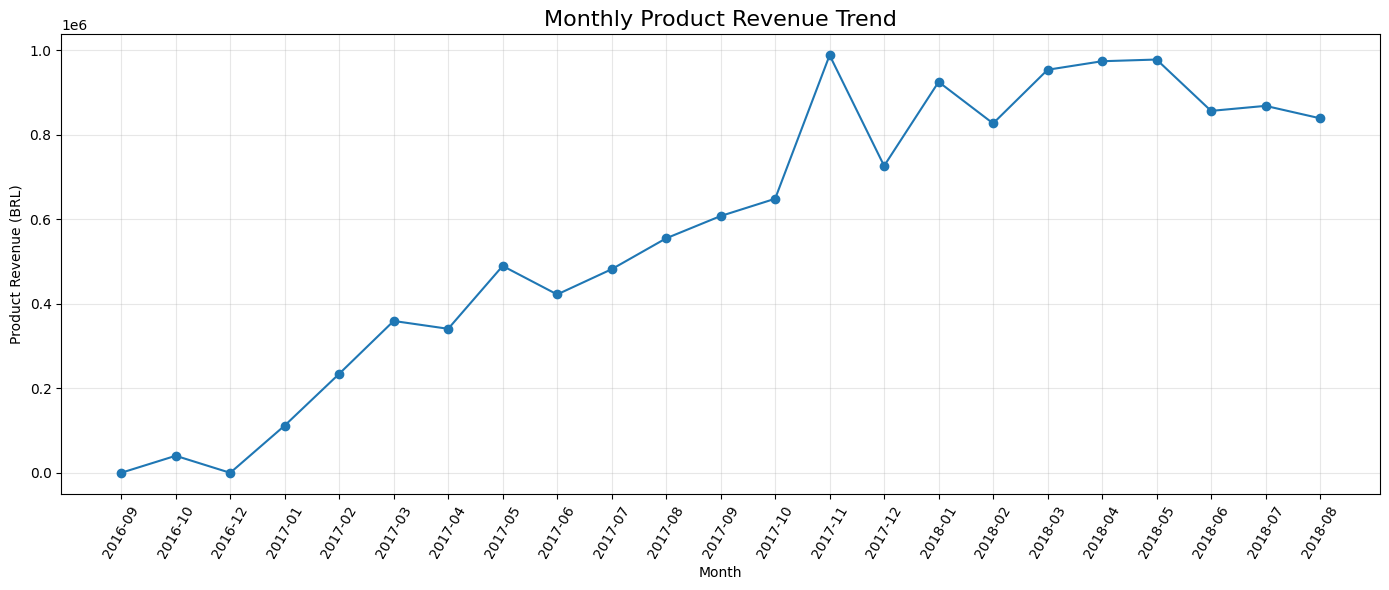

In [208]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales_summary["year_month"].astype(str),
    monthly_sales_summary["product_revenue"],
    marker="o"
)

plt.title("Monthly Product Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Product Revenue (BRL)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [209]:
#creates a complete monthly timeline
monthly_sales_complete = (
    monthly_sales_summary
    .set_index("year_month")
    .reindex(all_months)
)

#restores the month column
monthly_sales_complete.index.name = "year_month"
monthly_sales_complete = monthly_sales_complete.reset_index()

#fills missing monthly activity with zero
numeric_columns = [
    "total_orders",
    "total_items",
    "product_revenue",
    "freight_value",
    "total_sales_value"
]

monthly_sales_complete[numeric_columns] = (
    monthly_sales_complete[numeric_columns].fillna(0)
)

#recalculate AOV months without orders remain NaN
monthly_sales_complete["average_order_value"] = (
    monthly_sales_complete["product_revenue"]
    / monthly_sales_complete["total_orders"].replace(0, pd.NA)
)

display(monthly_sales_complete)

,year_month,total_orders,total_items,product_revenue,freight_value,total_sales_value,average_order_value
0,2016-09,1.0,3.0,134.97,8.49,143.46,134.97
1,2016-10,265.0,313.0,40325.11,6165.55,46490.66,152.170226
2,2016-11,0.0,0.0,0.00,0.00,0.00,<NA>
3,2016-12,1.0,1.0,10.90,8.72,19.62,10.9
4,2017-01,750.0,913.0,111798.36,15684.01,127482.37,149.06448
5,2017-02,1653.0,1858.0,234223.40,37015.92,271239.32,141.695947
6,2017-03,2546.0,2897.0,359198.85,55132.10,414330.95,141.083602
7,2017-04,2303.0,2569.0,340669.68,50142.72,390812.40,147.924307
8,2017-05,3546.0,4004.0,489338.25,77513.15,566851.40,137.99725
9,2017-06,3135.0,3489.0,421923.37,68127.00,490050.37,134.584807


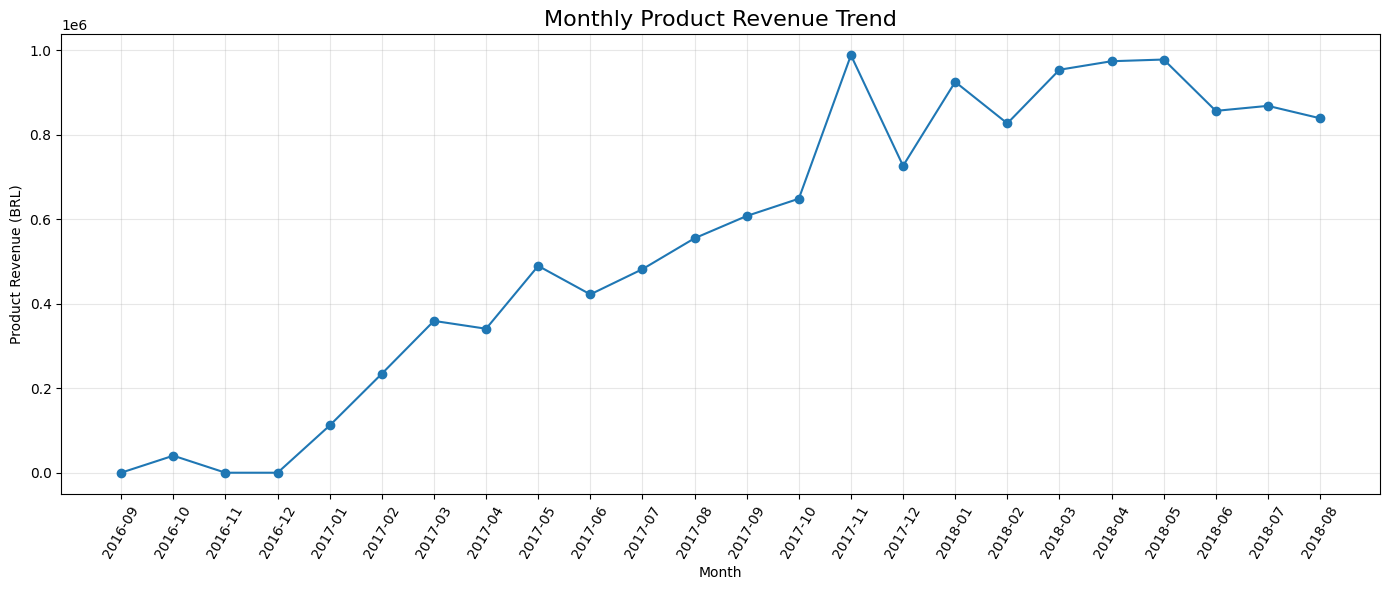

In [210]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales_complete["year_month"].astype(str),
    monthly_sales_complete["product_revenue"],
    marker="o"
)

plt.title("Monthly Product Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Product Revenue (BRL)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [211]:
monthly_sales_complete.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/monthly_sales_summary.csv",
    index=False
)

**Monthly Order Volume Analysis**

In [212]:
monthly_order_analysis = monthly_sales_complete[
    ["year_month", "total_orders", "total_items"]
].copy()

#calculate month over month change in orders
monthly_order_analysis["order_change"] = (
    monthly_order_analysis["total_orders"].diff()
)

#calculate month over month percentage change
monthly_order_analysis["order_growth_pct"] = (
    monthly_order_analysis["total_orders"]
    .pct_change(fill_method=None) * 100
)

display(monthly_order_analysis)

,year_month,total_orders,total_items,order_change,order_growth_pct
0,2016-09,1.0,3.0,NaN,NaN
1,2016-10,265.0,313.0,264.0,2.640000e+04
2,2016-11,0.0,0.0,-265.0,-1.000000e+02
3,2016-12,1.0,1.0,1.0,inf
4,2017-01,750.0,913.0,749.0,7.490000e+04
5,2017-02,1653.0,1858.0,903.0,1.204000e+02
6,2017-03,2546.0,2897.0,893.0,5.402299e+01
7,2017-04,2303.0,2569.0,-243.0,-9.544383e+00
8,2017-05,3546.0,4004.0,1243.0,5.397308e+01
9,2017-06,3135.0,3489.0,-411.0,-1.159052e+01


In [213]:
import numpy as np

monthly_order_analysis["order_growth_pct"] = (
    monthly_order_analysis["order_growth_pct"]
    .replace([np.inf, -np.inf], np.nan)
)

display(monthly_order_analysis)

,year_month,total_orders,total_items,order_change,order_growth_pct
0,2016-09,1.0,3.0,NaN,NaN
1,2016-10,265.0,313.0,264.0,26400.000000
2,2016-11,0.0,0.0,-265.0,-100.000000
3,2016-12,1.0,1.0,1.0,NaN
4,2017-01,750.0,913.0,749.0,74900.000000
5,2017-02,1653.0,1858.0,903.0,120.400000
6,2017-03,2546.0,2897.0,893.0,54.022989
7,2017-04,2303.0,2569.0,-243.0,-9.544383
8,2017-05,3546.0,4004.0,1243.0,53.973079
9,2017-06,3135.0,3489.0,-411.0,-11.590525


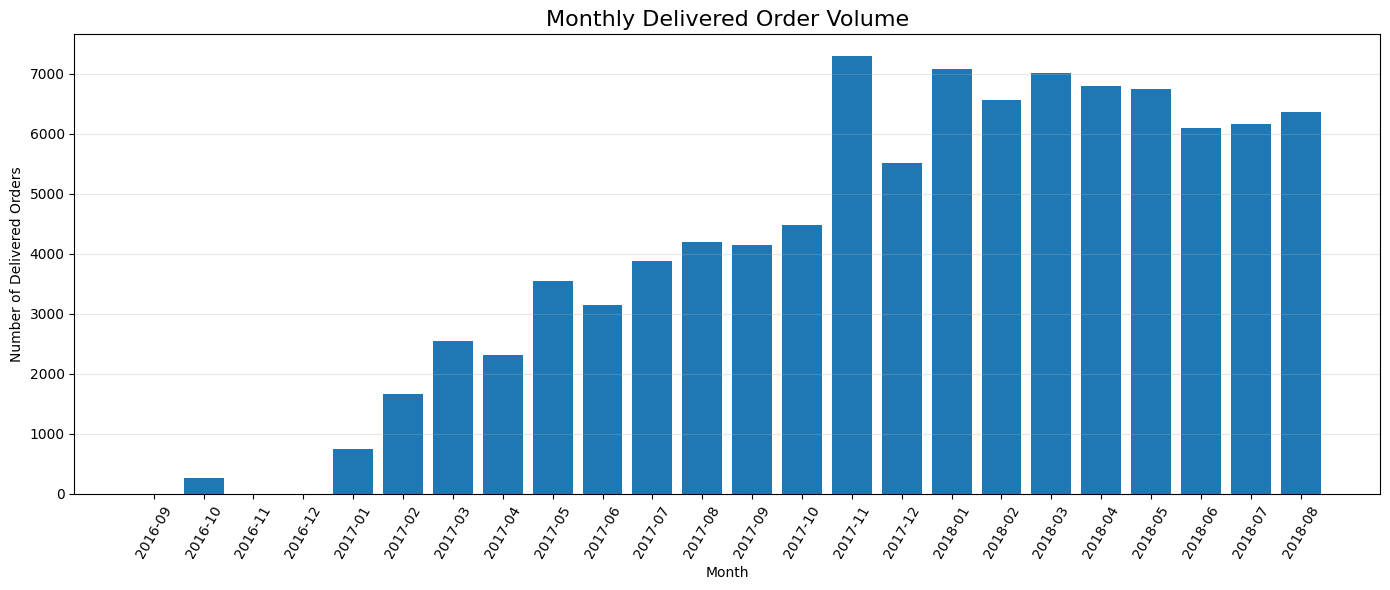

In [214]:
plt.figure(figsize=(14, 6))

plt.bar(
    monthly_order_analysis["year_month"].astype(str),
    monthly_order_analysis["total_orders"]
)

plt.title("Monthly Delivered Order Volume", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Number of Delivered Orders")
plt.xticks(rotation=60)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [215]:
monthly_order_analysis.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/monthly_order_analysis.csv",
    index=False
)

**Monthly Average Order Value Analysis**

In [216]:
monthly_aov_analysis = monthly_sales_complete[
    ["year_month", "total_orders", "product_revenue",
     "average_order_value"]
].copy()

#calculate month over month AOV change
monthly_aov_analysis["aov_change"] = (
    monthly_aov_analysis["average_order_value"].diff()
)

#calculate percentage change in AOV
monthly_aov_analysis["aov_growth_pct"] = (
    monthly_aov_analysis["average_order_value"]
    .pct_change(fill_method=None) * 100
)

display(monthly_aov_analysis)

,year_month,total_orders,product_revenue,average_order_value,aov_change,aov_growth_pct
0,2016-09,1.0,134.97,134.97,NaN,NaN
1,2016-10,265.0,40325.11,152.170226,17.200226,12.74374
2,2016-11,0.0,0.00,<NA>,<NA>,NaN
3,2016-12,1.0,10.90,10.9,<NA>,NaN
4,2017-01,750.0,111798.36,149.06448,138.16448,1267.564037
5,2017-02,1653.0,234223.40,141.695947,-7.368533,-4.943185
6,2017-03,2546.0,359198.85,141.083602,-0.612345,-0.432154
7,2017-04,2303.0,340669.68,147.924307,6.840706,4.848689
8,2017-05,3546.0,489338.25,137.99725,-9.927057,-6.710903
9,2017-06,3135.0,421923.37,134.584807,-3.412443,-2.472834


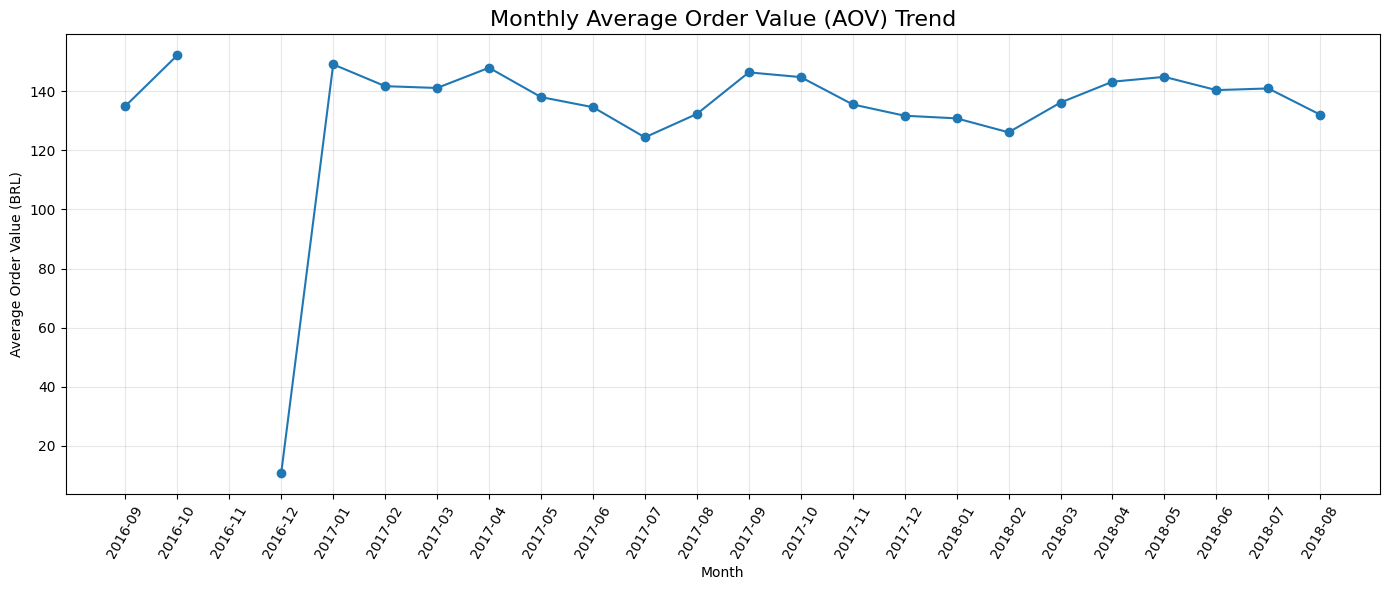

In [217]:
#create a plotting only copy
aov_plot_values = (
    monthly_aov_analysis["average_order_value"]
    .to_numpy(dtype="float64", na_value=np.nan)
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_aov_analysis["year_month"].astype(str),
    aov_plot_values,
    marker="o"
)

plt.title("Monthly Average Order Value (AOV) Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Average Order Value (BRL)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [218]:
monthly_aov_analysis.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/monthly_aov_analysis.csv",
    index=False
)

**Combin Monthly Sales KPIS**

In [219]:
monthly_sales_drivers = monthly_sales_complete[
    ["year_month", "product_revenue", "total_orders",
     "average_order_value"]
].copy()

display(monthly_sales_drivers)

,year_month,product_revenue,total_orders,average_order_value
0,2016-09,134.97,1.0,134.97
1,2016-10,40325.11,265.0,152.170226
2,2016-11,0.00,0.0,<NA>
3,2016-12,10.90,1.0,10.9
4,2017-01,111798.36,750.0,149.06448
5,2017-02,234223.40,1653.0,141.695947
6,2017-03,359198.85,2546.0,141.083602
7,2017-04,340669.68,2303.0,147.924307
8,2017-05,489338.25,3546.0,137.99725
9,2017-06,421923.37,3135.0,134.584807


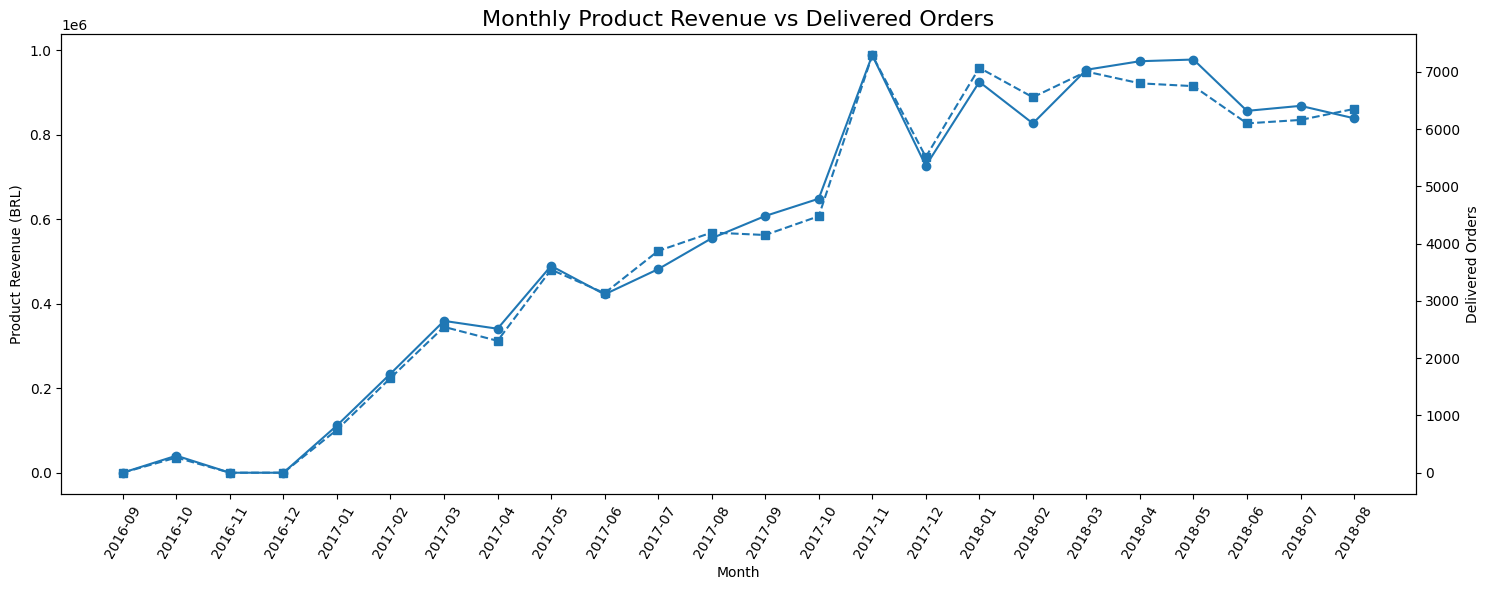

In [220]:
# Monthly revenue and order volume comparison

fig, ax1 = plt.subplots(figsize=(15, 6))

# Revenue
ax1.plot(
    monthly_sales_drivers["year_month"].astype(str),
    monthly_sales_drivers["product_revenue"],
    marker="o",
    label="Product Revenue"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Product Revenue (BRL)")
ax1.tick_params(axis="x", rotation=60)

# Order volume on second axis
ax2 = ax1.twinx()

ax2.plot(
    monthly_sales_drivers["year_month"].astype(str),
    monthly_sales_drivers["total_orders"],
    marker="s",
    linestyle="--",
    label="Delivered Orders"
)

ax2.set_ylabel("Delivered Orders")

plt.title("Monthly Product Revenue vs Delivered Orders", fontsize=16)

fig.tight_layout()
plt.show()

In [221]:
monthly_sales_drivers.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/monthly_sales_drivers.csv",
    index=False
)

**Annual Sales Peroformance**

In [222]:
monthly_sales_drivers["year"] = (
    monthly_sales_drivers["year_month"].dt.year
)

annual_sales_summary = (
    monthly_sales_drivers
    .groupby("year")
    .agg(
        product_revenue=("product_revenue", "sum"),
        total_orders=("total_orders", "sum")
    )
    .reset_index()
)

annual_sales_summary["average_order_value"] = (
    annual_sales_summary["product_revenue"]
    / annual_sales_summary["total_orders"]
)

display(annual_sales_summary)

,year,product_revenue,total_orders,average_order_value
0,2016,40470.98,267.0,151.576704
1,2017,5962902.01,43428.0,137.305471
2,2018,7218125.12,52783.0,136.750945


In [223]:
#like for like sales comparison

jan_aug_data = monthly_sales_drivers[
    (monthly_sales_drivers["year"].isin([2017, 2018])) &
    (monthly_sales_drivers["year_month"].dt.month <= 8)
].copy()

jan_aug_comparison = (
    jan_aug_data
    .groupby("year")
    .agg(
        product_revenue=("product_revenue", "sum"),
        total_orders=("total_orders", "sum")
    )
    .reset_index()
)

jan_aug_comparison["average_order_value"] = (
    jan_aug_comparison["product_revenue"]
    / jan_aug_comparison["total_orders"]
)

display(jan_aug_comparison)

,year,product_revenue,total_orders,average_order_value
0,2017,2993456.13,21998.0,136.078559
1,2018,7218125.12,52783.0,136.750945


In [224]:
#calculate year over year growth

revenue_growth = (
    jan_aug_comparison.loc[1, "product_revenue"]
    / jan_aug_comparison.loc[0, "product_revenue"] - 1
) * 100

order_growth = (
    jan_aug_comparison.loc[1, "total_orders"]
    / jan_aug_comparison.loc[0, "total_orders"] - 1
) * 100

aov_growth = (
    jan_aug_comparison.loc[1, "average_order_value"]
    / jan_aug_comparison.loc[0, "average_order_value"] - 1
) * 100

print(f"Product Revenue Growth: {revenue_growth:.2f}%")
print(f"Delivered Order Growth: {order_growth:.2f}%")
print(f"AOV Growth: {aov_growth:.2f}%")

Product Revenue Growth: 141.13%
Delivered Order Growth: 139.94%
AOV Growth: 0.49%


In [225]:
jan_aug_comparison.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/jan_aug_sales_comparison.csv",
    index=False
)

**Times Based Analysis**

In [226]:
orders_df = processed["orders"]

delivered_orders = orders_df[
    orders_df["order_status"] == "delivered"
].copy()

delivered_orders["day_of_week"] = (
    delivered_orders["order_purchase_timestamp"]
    .dt.day_name()
)

weekday_order_summary = (
    delivered_orders
    .groupby("day_of_week")
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

#arrange weekdays in calendar order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_order_summary["day_of_week"] = pd.Categorical(
    weekday_order_summary["day_of_week"],
    categories=weekday_order,
    ordered=True
)

weekday_order_summary = (
    weekday_order_summary
    .sort_values("day_of_week")
    .reset_index(drop=True)
)

display(weekday_order_summary)

,day_of_week,total_orders
0,Monday,15701
1,Tuesday,15503
2,Wednesday,15076
3,Thursday,14323
4,Friday,13685
5,Saturday,10555
6,Sunday,11635


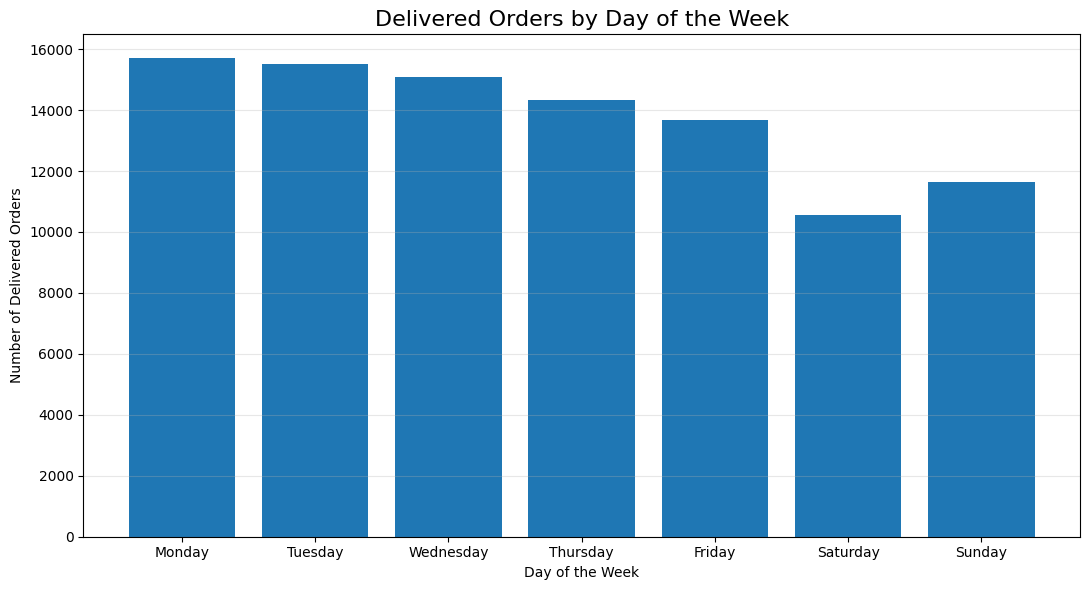

In [227]:
plt.figure(figsize=(11, 6))

plt.bar(
    weekday_order_summary["day_of_week"].astype(str),
    weekday_order_summary["total_orders"]
)

plt.title("Delivered Orders by Day of the Week", fontsize=16)
plt.xlabel("Day of the Week")
plt.ylabel("Number of Delivered Orders")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [228]:
weekday_order_summary.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/weekday_order_summary.csv",
    index=False
)

In [229]:
#orders by hour of the day

delivered_orders["purchase_hour"] = (
    delivered_orders["order_purchase_timestamp"].dt.hour
)

hourly_order_summary = (
    delivered_orders
    .groupby("purchase_hour")
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("purchase_hour")
)

display(hourly_order_summary)

,purchase_hour,total_orders
0,0,2321
1,1,1133
2,2,496
3,3,259
4,4,203
5,5,182
6,6,478
7,7,1199
8,8,2907
9,9,4647


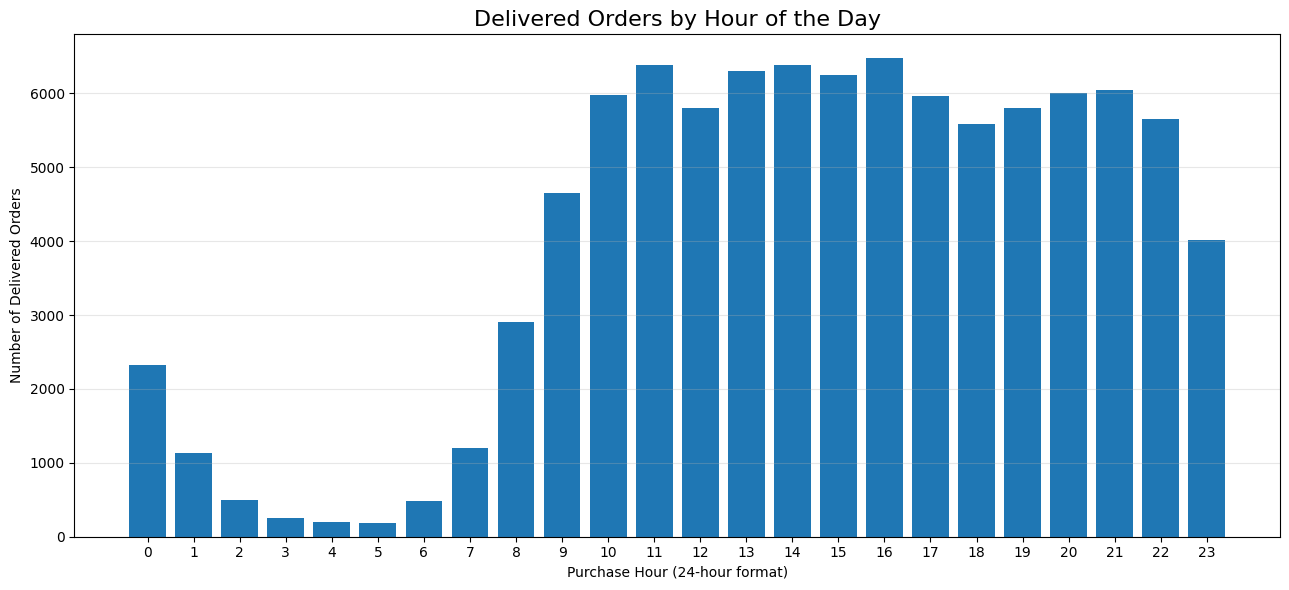

In [230]:
plt.figure(figsize=(13, 6))

plt.bar(
    hourly_order_summary["purchase_hour"],
    hourly_order_summary["total_orders"]
)

plt.title("Delivered Orders by Hour of the Day", fontsize=16)
plt.xlabel("Purchase Hour (24-hour format)")
plt.ylabel("Number of Delivered Orders")

plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [231]:
hourly_order_summary.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/hourly_order_summary.csv",
    index=False
)

In [232]:
#monthly seasonality

monthly_seasonality = monthly_sales_complete.copy()

monthly_seasonality["month_number"] = (
    monthly_seasonality["year_month"].dt.month
)

monthly_seasonality["month_name"] = (
    monthly_seasonality["year_month"]
    .dt.to_timestamp()
    .dt.month_name()
)

seasonality_summary = (
    monthly_seasonality
    .groupby(["month_number", "month_name"])
    .agg(
        average_orders=("total_orders", "mean"),
        total_orders=("total_orders", "sum"),
        months_observed=("total_orders", "count")
    )
    .reset_index()
    .sort_values("month_number")
)

display(seasonality_summary)

,month_number,month_name,average_orders,total_orders,months_observed
0,1,January,3909.5,7819.0,2
1,2,February,4104.0,8208.0,2
2,3,March,4774.5,9549.0,2
3,4,April,4550.5,9101.0,2
4,5,May,5147.5,10295.0,2
5,6,June,4617.0,9234.0,2
6,7,July,5015.5,10031.0,2
7,8,August,5272.0,10544.0,2
8,9,September,2075.5,4151.0,2
9,10,October,2371.5,4743.0,2


In [233]:
print(monthly_seasonality.columns.tolist())

['year_month', 'total_orders', 'total_items', 'product_revenue', 'freight_value', 'total_sales_value', 'average_order_value', 'month_number', 'month_name']


In [234]:
monthly_seasonality_summary = (
    monthly_seasonality
    .groupby(["month_number", "month_name"])
    .agg(
        average_orders=("total_orders", "mean"),
        total_orders=("total_orders", "sum"),
        months_observed=("total_orders", "count")
    )
    .reset_index()
    .sort_values("month_number")
)

display(monthly_seasonality_summary)

,month_number,month_name,average_orders,total_orders,months_observed
0,1,January,3909.5,7819.0,2
1,2,February,4104.0,8208.0,2
2,3,March,4774.5,9549.0,2
3,4,April,4550.5,9101.0,2
4,5,May,5147.5,10295.0,2
5,6,June,4617.0,9234.0,2
6,7,July,5015.5,10031.0,2
7,8,August,5272.0,10544.0,2
8,9,September,2075.5,4151.0,2
9,10,October,2371.5,4743.0,2


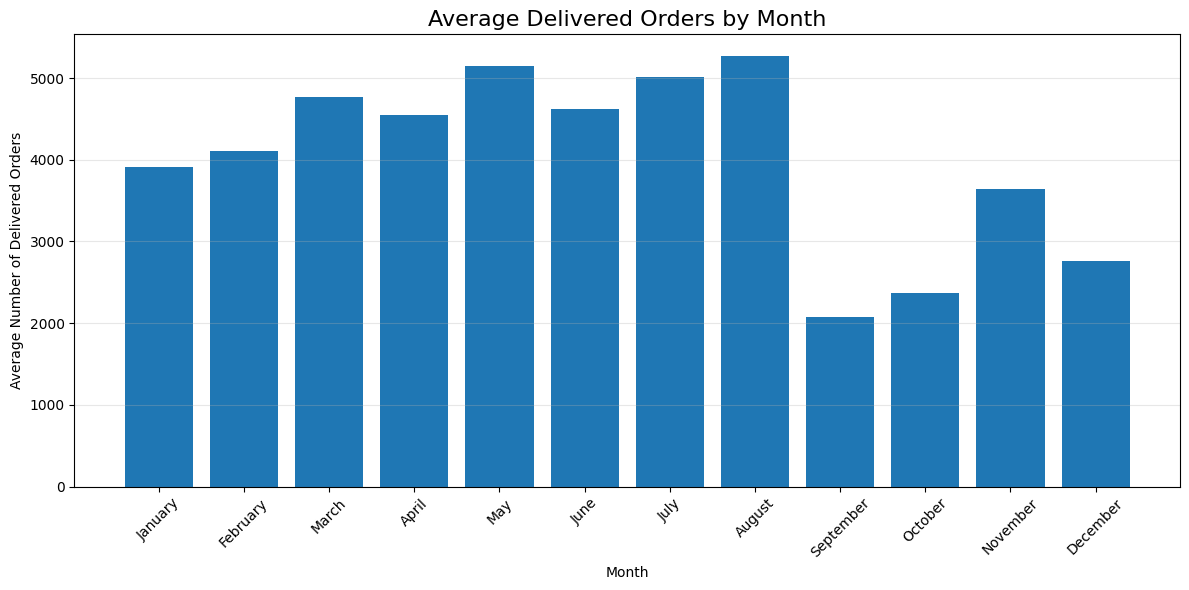

In [235]:
plt.figure(figsize=(12, 6))

plt.bar(
    monthly_seasonality_summary["month_name"],
    monthly_seasonality_summary["average_orders"]
)

plt.title("Average Delivered Orders by Month", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Average Number of Delivered Orders")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [236]:
monthly_seasonality_summary.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/monthly_seasonality.csv",
    index=False
)

In [237]:
#peak purchasing period
busiest_hour = hourly_order_summary.loc[
    hourly_order_summary["total_orders"].idxmax()
]

quietest_hour = hourly_order_summary.loc[
    hourly_order_summary["total_orders"].idxmin()
]

print("Busiest hour:")
display(busiest_hour)

print("Quietest hour:")
display(quietest_hour)

Busiest hour:


,16
purchase_hour,16
total_orders,6476


Quietest hour:


,5
purchase_hour,5
total_orders,182


In [238]:
#top 5 busiest purchasing hours

top_5_hours = (
    hourly_order_summary
    .sort_values("total_orders", ascending=False)
    .head(5)
)

display(top_5_hours)

,purchase_hour,total_orders
16,16,6476
11,11,6385
14,14,6383
13,13,6309
15,15,6249


In [239]:
#top 5 quietest purchasing hours

bottom_5_hours = (
    hourly_order_summary
    .sort_values("total_orders", ascending=True)
    .head(5)
)

display(bottom_5_hours)

,purchase_hour,total_orders
5,5,182
4,4,203
3,3,259
6,6,478
2,2,496


In [240]:
hourly_order_summary.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/hourly_order_summary.csv",
    index=False
)

In [241]:
top_5_hours.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/top_5_purchase_hours.csv",
    index=False
)

bottom_5_hours.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/bottom_5_purchase_hours.csv",
    index=False
)

In [242]:
#customer base analysis

customers_df = processed["customers"]
orders_df = processed["orders"]

delivered_orders = orders_df[
    orders_df["order_status"] == "delivered"
].copy()

total_unique_customers = customers_df["customer_unique_id"].nunique()

customers_with_orders = delivered_orders["customer_id"].nunique()

unique_buyers = delivered_orders.merge(
    customers_df[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)["customer_unique_id"].nunique()

print("Total customer records:", len(customers_df))
print("Unique customer identities:", total_unique_customers)
print("Customers with delivered orders:", customers_with_orders)
print("Unique buyers with delivered orders:", unique_buyers)

Total customer records: 99441
Unique customer identities: 96096
Customers with delivered orders: 96478
Unique buyers with delivered orders: 93358


**Repeat Customer Analysis**

In [243]:
#repeat customer analysis

delivered_customer_orders = delivered_orders.merge(
    customers_df[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

customer_order_frequency = (
    delivered_customer_orders
    .groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

#classify customers by order frequency
repeat_customer_summary = (
    customer_order_frequency
    .assign(
        customer_type=lambda df: df["total_orders"].apply(
            lambda x: "Repeat Customer" if x > 1 else "One-time Customer"
        )
    )
    .groupby("customer_type")
    .agg(
        total_customers=("customer_unique_id", "nunique")
    )
    .reset_index()
)

display(repeat_customer_summary)

,customer_type,total_customers
0,One-time Customer,90557
1,Repeat Customer,2801


In [244]:
#repeat purchase rate

total_buyers = customer_order_frequency["customer_unique_id"].nunique()

repeat_customers = customer_order_frequency[
    customer_order_frequency["total_orders"] > 1
]["customer_unique_id"].nunique()

one_time_customers = customer_order_frequency[
    customer_order_frequency["total_orders"] == 1
]["customer_unique_id"].nunique()

repeat_purchase_rate = (
    repeat_customers / total_buyers
) * 100

one_time_customer_rate = (
    one_time_customers / total_buyers
) * 100

print("Total unique buyers:", total_buyers)
print("Repeat customers:", repeat_customers)
print("One-time customers:", one_time_customers)
print(f"Repeat purchase rate: {repeat_purchase_rate:.2f}%")
print(f"One-time customer rate: {one_time_customer_rate:.2f}%")

Total unique buyers: 93358
Repeat customers: 2801
One-time customers: 90557
Repeat purchase rate: 3.00%
One-time customer rate: 97.00%


In [245]:
#orders per customer distribution

orders_per_customer_summary = (
    customer_order_frequency
    .groupby("total_orders")
    .agg(
        total_customers=("customer_unique_id", "nunique")
    )
    .reset_index()
    .sort_values("total_orders")
)

orders_per_customer_summary["customer_percentage"] = (
    orders_per_customer_summary["total_customers"]
    / total_buyers
) * 100

display(orders_per_customer_summary)

,total_orders,total_customers,customer_percentage
0,1,90557,96.999722
1,2,2573,2.756057
2,3,181,0.193877
3,4,28,0.029992
4,5,9,0.009640
5,6,5,0.005356
6,7,3,0.003213
7,9,1,0.001071
8,15,1,0.001071


In [246]:
orders_per_customer_summary.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/orders_per_customer_summary.csv",
    index=False
)

In [247]:
#customer geographic distribution

customer_state_summary = (
    customers_df
    .groupby("customer_state")
    .agg(
        total_customers=("customer_unique_id", "nunique")
    )
    .reset_index()
    .sort_values("total_customers", ascending=False)
)

customer_state_summary["customer_percentage"] = (
    customer_state_summary["total_customers"]
    / customer_state_summary["total_customers"].sum()
) * 100

display(customer_state_summary.head(10))

,customer_state,total_customers,customer_percentage
25,SP,40302,41.921861
18,RJ,12384,12.881751
10,MG,11259,11.711534
22,RS,5277,5.489099
17,PR,4882,5.078223
23,SC,3534,3.676042
4,BA,3277,3.408713
6,DF,2075,2.158401
7,ES,1964,2.042939
8,GO,1952,2.030457


In [248]:
customer_state_summary.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/customer_state_summary.csv",
    index=False
)

In [249]:
#geographic concentration

top_3_share = customer_state_summary.head(3)["customer_percentage"].sum()
top_5_share = customer_state_summary.head(5)["customer_percentage"].sum()
top_10_share = customer_state_summary.head(10)["customer_percentage"].sum()

print(f"Top 3 states customer share: {top_3_share:.2f}%")
print(f"Top 5 states customer share: {top_5_share:.2f}%")
print(f"Top 10 states customer share: {top_10_share:.2f}%")

Top 3 states customer share: 66.52%
Top 5 states customer share: 77.08%
Top 10 states customer share: 90.40%


In [250]:
#average orders per customer

average_orders_per_customer = (
    customer_order_frequency["total_orders"].mean()
)

median_orders_per_customer = (
    customer_order_frequency["total_orders"].median()
)

print(f"Average orders per customer: {average_orders_per_customer:.2f}")
print(f"Median orders per customer: {median_orders_per_customer:.0f}")

Average orders per customer: 1.03
Median orders per customer: 1


In [251]:
#orders generated by customer type

customer_order_type_summary = (
    customer_order_frequency
    .assign(
        customer_type=lambda df: df["total_orders"].apply(
            lambda x: "Repeat Customer" if x > 1 else "One-time Customer"
        )
    )
    .groupby("customer_type")
    .agg(
        total_customers=("customer_unique_id", "nunique"),
        total_orders=("total_orders", "sum"),
        average_orders_per_customer=("total_orders", "mean")
    )
    .reset_index()
)

customer_order_type_summary["order_percentage"] = (
    customer_order_type_summary["total_orders"]
    / customer_order_type_summary["total_orders"].sum()
) * 100

display(customer_order_type_summary)

,customer_type,total_customers,total_orders,average_orders_per_customer,order_percentage
0,One-time Customer,90557,90557,1.000000,93.86285
1,Repeat Customer,2801,5921,2.113888,6.13715


In [252]:
customer_order_type_summary.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/customer_order_type_summary.csv",
    index=False
)

**Product Analysis**

In [253]:
#product category performance

delivered_items = processed["order_items"][
    processed["order_items"]["order_id"].isin(
        delivered_orders["order_id"]
    )
].copy()

products_df = processed["products"]

delivered_product_data = delivered_items.merge(
    products_df[
        ["product_id", "product_category_name_english"]
    ],
    on="product_id",
    how="left"
)

#label products with missing categories
delivered_product_data["product_category_name_english"] = (
    delivered_product_data["product_category_name_english"]
    .fillna("Unknown")
)

category_revenue_summary = (
    delivered_product_data
    .groupby("product_category_name_english")
    .agg(
        total_items=("order_item_id", "count"),
        total_orders=("order_id", "nunique"),
        product_revenue=("price", "sum")
    )
    .reset_index()
    .sort_values("product_revenue", ascending=False)
)

display(category_revenue_summary.head(10))

,product_category_name_english,total_items,total_orders,product_revenue
45,health_beauty,9465,8647,1233131.72
73,watches_gifts,5859,5495,1166176.98
8,bed_bath_table,10953,9272,1023434.76
68,sports_leisure,8431,7530,954852.55
16,computers_accessories,7644,6530,888724.61
40,furniture_decor,8160,6307,711927.69
51,housewares,6795,5743,615628.69
21,cool_stuff,3718,3559,610204.10
6,auto,4140,3810,578966.65
72,toys,4030,3804,471286.48


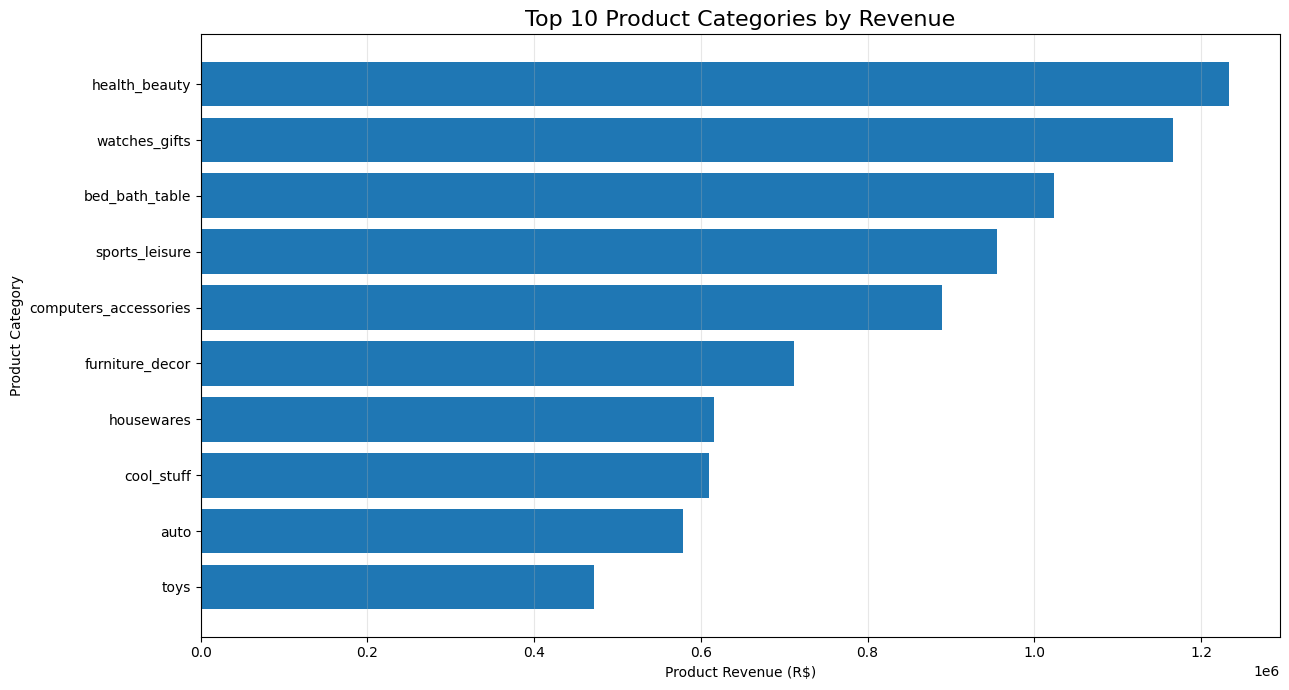

In [254]:
plt.figure(figsize=(13, 7))

top_10_categories = category_revenue_summary.head(10).sort_values(
    "product_revenue",
    ascending=True
)

plt.barh(
    top_10_categories["product_category_name_english"],
    top_10_categories["product_revenue"]
)

plt.title("Top 10 Product Categories by Revenue", fontsize=16)
plt.xlabel("Product Revenue (R$)")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [255]:
category_revenue_summary.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/category_revenue_summary.csv",
    index=False
)

In [256]:
#top categories by item quantity

category_quantity_summary = (
    category_revenue_summary
    .sort_values("total_items", ascending=False)
    .reset_index(drop=True)
)

display(category_quantity_summary.head(10))

,product_category_name_english,total_items,total_orders,product_revenue
0,bed_bath_table,10953,9272,1023434.76
1,health_beauty,9465,8647,1233131.72
2,sports_leisure,8431,7530,954852.55
3,furniture_decor,8160,6307,711927.69
4,computers_accessories,7644,6530,888724.61
5,housewares,6795,5743,615628.69
6,watches_gifts,5859,5495,1166176.98
7,telephony,4430,4093,309860.23
8,garden_tools,4268,3448,470495.28
9,auto,4140,3810,578966.65


In [257]:
#average selling price by category

category_revenue_summary["average_selling_price"] = (
    category_revenue_summary["product_revenue"]
    / category_revenue_summary["total_items"]
)

category_price_summary = (
    category_revenue_summary
    .sort_values("average_selling_price", ascending=False)
    .reset_index(drop=True)
)

display(category_price_summary[
    [
        "product_category_name_english",
        "total_items",
        "product_revenue",
        "average_selling_price"
    ]
].head(10))

,product_category_name_english,total_items,product_revenue,average_selling_price
0,computers,199,218684.14,1098.915276
1,small_appliances_home_oven_and_coffee,73,46589.56,638.213151
2,home_appliances_2,231,107953.95,467.333117
3,agro_industry_and_commerce,206,70566.10,342.553883
4,musical_instruments,651,184315.74,283.127097
5,portable_kitchen_and_food_processors,14,3933.63,280.973571
6,small_appliances,658,182754.12,277.741824
7,fixed_telephony,255,55315.21,216.922392
8,construction_tools_safety,183,38773.22,211.875519
9,watches_gifts,5859,1166176.98,199.040276


In [258]:
#product revenue concentration

category_concentration = category_revenue_summary.copy()

category_concentration = category_concentration.sort_values(
    "product_revenue",
    ascending=False
).reset_index(drop=True)

total_category_revenue = category_concentration["product_revenue"].sum()

category_concentration["revenue_share_pct"] = (
    category_concentration["product_revenue"]
    / total_category_revenue
) * 100

category_concentration["cumulative_revenue_share_pct"] = (
    category_concentration["revenue_share_pct"].cumsum()
)

display(
    category_concentration[
        [
            "product_category_name_english",
            "product_revenue",
            "revenue_share_pct",
            "cumulative_revenue_share_pct"
        ]
    ].head(15)
)

,product_category_name_english,product_revenue,revenue_share_pct,cumulative_revenue_share_pct
0,health_beauty,1233131.72,9.326717,9.326717
1,watches_gifts,1166176.98,8.820309,18.147026
2,bed_bath_table,1023434.76,7.740687,25.887713
3,sports_leisure,954852.55,7.221969,33.109682
4,computers_accessories,888724.61,6.721815,39.831497
5,furniture_decor,711927.69,5.384622,45.216119
6,housewares,615628.69,4.656270,49.872389
7,cool_stuff,610204.10,4.615242,54.487631
8,auto,578966.65,4.378979,58.866610
9,toys,471286.48,3.564547,62.431157


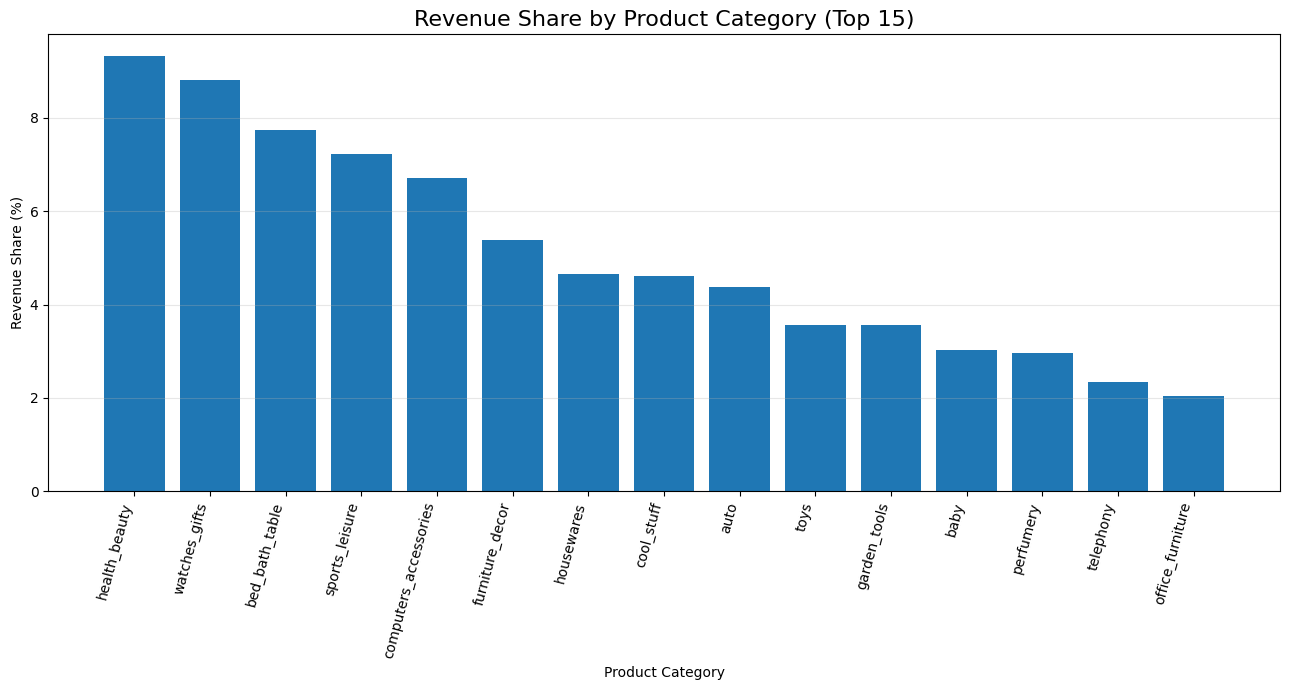

In [259]:
#top 15 categories: cumulative revenue contribution

plt.figure(figsize=(13, 7))

plt.bar(
    category_concentration.head(15)[
        "product_category_name_english"
    ],
    category_concentration.head(15)["revenue_share_pct"]
)

plt.title("Revenue Share by Product Category (Top 15)", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Revenue Share (%)")
plt.xticks(rotation=75, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [260]:
category_concentration.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/category_revenue_concentration.csv",
    index=False
)

In [261]:
#product level performance

product_performance = (
    delivered_product_data
    .groupby("product_id")
    .agg(
        total_items=("order_item_id", "count"),
        total_orders=("order_id", "nunique"),
        product_revenue=("price", "sum")
    )
    .reset_index()
)

#add product category
product_performance = product_performance.merge(
    products_df[
        ["product_id", "product_category_name_english"]
    ],
    on="product_id",
    how="left"
)

#top 10 products by revenue
top_products_by_revenue = product_performance.sort_values(
    "product_revenue",
    ascending=False
).head(10)

display(top_products_by_revenue)

,product_id,total_items,total_orders,product_revenue,product_category_name_english
23546,bb50f2e236e5eea0100680137654686c,194,186,63560.00,health_beauty
13749,6cdd53843498f92890544667809f1595,153,148,53652.30,health_beauty
26997,d6160fb7873f184099d9bc95e30376af,33,33,45949.35,computers
26436,d1c427060a0f73f6b889a5c7c61f2ac4,332,313,45620.56,computers_accessories
19290,99a4788cb24856965c36a24e339b6058,477,456,42049.66,bed_bath_table
7881,3dd2a17168ec895c781a9191c1e95ad7,272,253,40782.80,computers_accessories
4892,25c38557cf793876c5abdd5931f922db,38,38,38907.32,baby
12074,5f504b3a1c75b73d6151be81eb05bdc9,63,63,37733.90,cool_stuff
10616,53b36df67ebb7c41585e8d54d6772e08,321,304,37454.63,watches_gifts
21617,aca2eb7d00ea1a7b8ebd4e68314663af,520,425,37104.30,furniture_decor


In [262]:
#top products by quantity sold

top_products_by_quantity = (
    product_performance
    .sort_values(
        ["total_items", "product_revenue"],
        ascending=[False, False]
    )
    .head(10)
)

display(top_products_by_quantity)

,product_id,total_items,total_orders,product_revenue,product_category_name_english
21617,aca2eb7d00ea1a7b8ebd4e68314663af,520,425,37104.30,furniture_decor
8429,422879e10f46682990de24d770e7f83d,484,352,26577.22,garden_tools
19290,99a4788cb24856965c36a24e339b6058,477,456,42049.66,bed_bath_table
7206,389d119b48cf3043d311335e499d9c6b,390,309,21336.79,garden_tools
6926,368c6c730842d78016ad823897a372db,388,291,21056.80,garden_tools
10589,53759a2ecddad2bb87a079a1f1519f73,373,287,20387.20,garden_tools
26436,d1c427060a0f73f6b889a5c7c61f2ac4,332,313,45620.56,computers_accessories
10616,53b36df67ebb7c41585e8d54d6772e08,321,304,37454.63,watches_gifts
2734,154e7e31ebfa092203795c972e5804a6,274,262,6173.26,health_beauty
7881,3dd2a17168ec895c781a9191c1e95ad7,272,253,40782.80,computers_accessories


In [263]:
#complete product performance data
product_performance.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/product_performance.csv",
    index=False
)

#top 10 by revenue
top_products_by_revenue.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/top_products_by_revenue.csv",
    index=False
)

#top 10 by quantity
top_products_by_quantity.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/top_products_by_quantity.csv",
    index=False
)

In [264]:
#category revenue vs quantity

category_performance_comparison = category_revenue_summary[
    [
        "product_category_name_english",
        "total_items",
        "product_revenue"
    ]
].copy()

category_performance_comparison["average_selling_price"] = (
    category_performance_comparison["product_revenue"]
    / category_performance_comparison["total_items"]
)

category_performance_comparison = (
    category_performance_comparison
    .sort_values("product_revenue", ascending=False)
    .reset_index(drop=True)
)

display(category_performance_comparison.head(15))

,product_category_name_english,total_items,product_revenue,average_selling_price
0,health_beauty,9465,1233131.72,130.283330
1,watches_gifts,5859,1166176.98,199.040276
2,bed_bath_table,10953,1023434.76,93.438762
3,sports_leisure,8431,954852.55,113.254958
4,computers_accessories,7644,888724.61,116.264339
5,furniture_decor,8160,711927.69,87.246040
6,housewares,6795,615628.69,90.600249
7,cool_stuff,3718,610204.10,164.121598
8,auto,4140,578966.65,139.847017
9,toys,4030,471286.48,116.944536


In [265]:
category_performance_comparison.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/category_performance_comparison.csv",
    index=False
)

In [266]:
#overall product analysis KPIs

total_products_sold = delivered_product_data["product_id"].nunique()

total_items_sold = delivered_product_data["order_item_id"].count()

total_categories_sold = (
    delivered_product_data["product_category_name_english"].nunique()
)

overall_average_selling_price = (
    delivered_product_data["price"].sum()
    / total_items_sold
)

print("Unique products sold:", total_products_sold)
print("Total items sold:", total_items_sold)
print("Product categories sold:", total_categories_sold)
print(
    "Overall average selling price:",
    round(overall_average_selling_price, 2)
)

Unique products sold: 32216
Total items sold: 110197
Product categories sold: 74
Overall average selling price: 119.98


**Seller Analysis**

In [267]:
#total active sellers

sellers_df = processed["sellers"]

active_seller_ids = delivered_items["seller_id"].unique()

total_registered_sellers = sellers_df["seller_id"].nunique()
total_active_sellers = len(active_seller_ids)
inactive_sellers = total_registered_sellers - total_active_sellers

print("Total registered sellers:", total_registered_sellers)
print("Total active sellers:", total_active_sellers)
print("Sellers without delivered sales:", inactive_sellers)

print(
    "Active seller percentage:",
    round(total_active_sellers / total_registered_sellers * 100, 2),
    "%"
)

Total registered sellers: 3095
Total active sellers: 2970
Sellers without delivered sales: 125
Active seller percentage: 95.96 %


In [268]:
#orders handled by each seller

seller_order_summary = (
    delivered_items
    .groupby("seller_id")
    .agg(
        total_items=("order_item_id", "count"),
        total_orders=("order_id", "nunique"),
        product_revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum")
    )
    .reset_index()
)

seller_order_summary = seller_order_summary.sort_values(
    "total_orders",
    ascending=False
).reset_index(drop=True)

display(seller_order_summary.head(10))

,seller_id,total_items,total_orders,product_revenue,freight_revenue
0,6560211a19b47992c3666cc44a7e94c0,1996,1819,120702.83,27348.11
1,4a3ca9315b744ce9f8e9374361493884,1949,1772,196882.12,34338.31
2,cc419e0650a3c5ba77189a1882b7556a,1719,1651,101090.96,24846.03
3,1f50f920176fa81dab994f9023523100,1926,1399,106655.71,35057.23
4,da8622b14eb17ae2831f4ac5b9dab84a,1548,1311,159816.87,24889.91
5,955fee9216a65b617aa5c0531780ce60,1472,1261,131836.71,24769.77
6,7a67c85e85bb2ce8582c35f2203ad736,1155,1145,139658.69,20619.83
7,ea8482cd71df3c1969d7b9473ff13abc,1188,1132,36696.76,17291.87
8,4869f7a5dfa277a7dca6462dcf3b52b2,1148,1124,226987.93,20019.13
9,3d871de0142ce09b7081e2b9d1733cb1,1131,1064,93407.40,22108.25


In [269]:
#top sellers by product revenue

top_sellers_by_revenue = (
    seller_order_summary
    .sort_values("product_revenue", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(top_sellers_by_revenue)

,seller_id,total_items,total_orders,product_revenue,freight_revenue
0,4869f7a5dfa277a7dca6462dcf3b52b2,1148,1124,226987.93,20019.13
1,53243585a1d6dc2643021fd1853d8905,400,348,217940.44,12856.58
2,4a3ca9315b744ce9f8e9374361493884,1949,1772,196882.12,34338.31
3,fa1c13f2614d7b5c4749cbc52fecda94,579,578,190917.14,9916.36
4,7c67e1448b00f6e969d365cea6b010ab,1355,973,186570.05,51236.64
5,7e93a43ef30c4f03f38b393420bc753a,322,319,165981.49,5992.06
6,da8622b14eb17ae2831f4ac5b9dab84a,1548,1311,159816.87,24889.91
7,7a67c85e85bb2ce8582c35f2203ad736,1155,1145,139658.69,20619.83
8,1025f0e2d44d7041d6cf58b6550e0bfa,1420,910,138208.56,33716.40
9,955fee9216a65b617aa5c0531780ce60,1472,1261,131836.71,24769.77


In [270]:
#average product revenue per order

seller_order_summary["average_revenue_per_order"] = (
    seller_order_summary["product_revenue"]
    / seller_order_summary["total_orders"]
)

seller_order_value_summary = (
    seller_order_summary
    .sort_values("average_revenue_per_order", ascending=False)
    .reset_index(drop=True)
)

display(
    seller_order_value_summary[
        [
            "seller_id",
            "total_orders",
            "product_revenue",
            "average_revenue_per_order"
        ]
    ].head(10)
)

,seller_id,total_orders,product_revenue,average_revenue_per_order
0,e3b4998c7a498169dc7bce44e6bb6277,1,6735.00,6735.000000
1,80ceebb4ee9b31afb6c6a916a574a1e2,1,6729.00,6729.000000
2,ee27a8f15b1dded4d213a468ba4eb391,1,6499.00,6499.000000
3,b37c4c02bda3161a7546a4e6d222d5b2,4,24075.00,6018.750000
4,585175ec331ea177fa47199e39a6170a,1,3549.00,3549.000000
5,abe021b01ba992245271b9aa422032df,2,6720.00,3360.000000
6,a00824eb9093d40e589b940ec45c4eb0,3,9399.97,3133.323333
7,e2a1ac9bf33e5549a2a4f834e70df2f8,5,14999.45,2999.890000
8,e908c0f3646e8b60375734a350d95d71,1,2951.00,2951.000000
9,d63c73efd41eb002280e7ec831424edb,2,5598.00,2799.000000


In [271]:
#filter sellers with at least 20 delivered orders

established_sellers = seller_order_summary[
    seller_order_summary["total_orders"] >= 20
].copy()

established_sellers["average_revenue_per_order"] = (
    established_sellers["product_revenue"]
    / established_sellers["total_orders"]
)

established_sellers = established_sellers.sort_values(
    "average_revenue_per_order",
    ascending=False
).reset_index(drop=True)

display(
    established_sellers[
        [
            "seller_id",
            "total_orders",
            "total_items",
            "product_revenue",
            "average_revenue_per_order"
        ]
    ].head(10)
)

,seller_id,total_orders,total_items,product_revenue,average_revenue_per_order
0,2bf6a2c1e71bbd29a4ad64e6d3c3629f,30,31,50628.90,1687.630000
1,b839e41795b7f3ad94cc2014a52f6796,33,36,42829.00,1297.848485
2,ba90964cff9b9e0e6f32b23b82465f7b,38,38,44212.50,1163.486842
3,ff69aa92bb6b1bf9b8b7a51c2ed9cf8b,20,20,21940.80,1097.040000
4,e882b2a25a10b9c057cc49695f222c19,57,58,51057.54,895.746316
5,17f51e7198701186712e53a39c564617,56,61,48019.00,857.482143
6,c72de06d72748d1a0dfb2125be43ba63,21,22,17522.00,834.380952
7,f62d7bb4a613ec758a03342d46b580b2,32,32,24665.00,770.781250
8,f9244d45189d3a3605499abddeade7d5,20,20,15081.44,754.072000
9,d23019c84ffae2d5ef2270367b8605fc,39,39,29205.10,748.848718


In [272]:
#seller revenue concentration

seller_concentration = (
    seller_order_summary
    .sort_values("product_revenue", ascending=False)
    .reset_index(drop=True)
    .copy()
)

total_seller_revenue = seller_concentration["product_revenue"].sum()

seller_concentration["revenue_share_pct"] = (
    seller_concentration["product_revenue"]
    / total_seller_revenue
) * 100

seller_concentration["cumulative_revenue_share_pct"] = (
    seller_concentration["revenue_share_pct"].cumsum()
)

# Calculate concentration at different seller rankings
for n in [10, 50, 100]:
    share = seller_concentration.head(n)["revenue_share_pct"].sum()
    print(f"Top {n} sellers' revenue share: {share:.2f}%")

display(seller_concentration.head(15))

Top 10 sellers' revenue share: 13.27%
Top 50 sellers' revenue share: 33.20%
Top 100 sellers' revenue share: 45.52%


,seller_id,total_items,total_orders,product_revenue,freight_revenue,average_revenue_per_order,revenue_share_pct,cumulative_revenue_share_pct
0,4869f7a5dfa277a7dca6462dcf3b52b2,1148,1124,226987.93,20019.13,201.946557,1.716809,1.716809
1,53243585a1d6dc2643021fd1853d8905,400,348,217940.44,12856.58,626.265632,1.648379,3.365189
2,4a3ca9315b744ce9f8e9374361493884,1949,1772,196882.12,34338.31,111.107291,1.489106,4.854295
3,fa1c13f2614d7b5c4749cbc52fecda94,579,578,190917.14,9916.36,330.306471,1.443990,6.298285
4,7c67e1448b00f6e969d365cea6b010ab,1355,973,186570.05,51236.64,191.747225,1.411111,7.709396
5,7e93a43ef30c4f03f38b393420bc753a,322,319,165981.49,5992.06,520.318150,1.255391,8.964787
6,da8622b14eb17ae2831f4ac5b9dab84a,1548,1311,159816.87,24889.91,121.904554,1.208765,10.173552
7,7a67c85e85bb2ce8582c35f2203ad736,1155,1145,139658.69,20619.83,121.972655,1.056300,11.229852
8,1025f0e2d44d7041d6cf58b6550e0bfa,1420,910,138208.56,33716.40,151.877538,1.045332,12.275185
9,955fee9216a65b617aa5c0531780ce60,1472,1261,131836.71,24769.77,104.549334,0.997139,13.272323


In [273]:
#geographic distribution of active sellers

seller_geographic_data = seller_order_summary.merge(
    sellers_df[["seller_id", "seller_state", "seller_city"]],
    on="seller_id",
    how="left"
)

seller_state_summary = (
    seller_geographic_data
    .groupby("seller_state")
    .agg(
        total_sellers=("seller_id", "nunique"),
        total_orders=("total_orders", "sum"),
        total_items=("total_items", "sum"),
        product_revenue=("product_revenue", "sum")
    )
    .reset_index()
)

seller_state_summary = seller_state_summary.sort_values(
    "product_revenue",
    ascending=False
).reset_index(drop=True)

seller_state_summary["seller_percentage"] = (
    seller_state_summary["total_sellers"]
    / seller_state_summary["total_sellers"].sum()
) * 100

seller_state_summary["revenue_share_pct"] = (
    seller_state_summary["product_revenue"]
    / seller_state_summary["product_revenue"].sum()
) * 100

display(seller_state_summary.head(15))

,seller_state,total_sellers,total_orders,total_items,product_revenue,seller_percentage,revenue_share_pct
0,SP,1769,69401,78604,8509511.46,59.562290,64.361174
1,PR,335,7556,8487,1232096.99,11.279461,9.318891
2,MG,236,7747,8603,977866.31,7.946128,7.396033
3,RJ,163,4229,4685,820611.59,5.488215,6.206646
4,SC,184,3608,4000,613591.65,6.195286,4.640863
5,RS,125,1964,2169,373412.08,4.208754,2.824280
6,BA,18,550,624,277925.51,0.606061,2.102073
7,DF,30,808,883,94840.31,1.010101,0.717319
8,PE,9,403,445,91164.15,0.303030,0.689515
9,GO,39,451,508,64806.59,1.313131,0.490161


**Delivery Analysis**

In [274]:
#calculate actual delivery time

delivered_orders = processed["orders"][
    processed["orders"]["order_status"] == "delivered"
].copy()

delivered_orders["actual_delivery_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

#display summary statistics
display(
    delivered_orders["actual_delivery_days"].describe()
)

,actual_delivery_days
count,96470.000000
mean,12.558217
std,9.546156
min,0.533414
25%,6.766204
50%,10.217477
75%,15.720182
max,209.628611


In [275]:
#investigate long delivery durations

long_delivery_orders = delivered_orders[
    delivered_orders["actual_delivery_days"] > 60
].copy()

print("Orders taking more than 60 days:",
      len(long_delivery_orders))

display(
    long_delivery_orders[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
            "actual_delivery_days"
        ]
    ].sort_values(
        "actual_delivery_days",
        ascending=False
    ).head(10)
)

Orders taking more than 60 days: 306


,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_days
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,209.628611
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,208.351759
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,195.634016
70307,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:02,2017-09-19 14:33:17,2017-04-17,194.850174
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,194.633611
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,194.049583
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,191.463542
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,189.863160
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,188.134618
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,187.743843


In [276]:
#summarize long delivery durations

delivery_duration_bands = pd.cut(
    delivered_orders["actual_delivery_days"],
    bins=[0, 7, 14, 30, 60, float("inf")],
    labels=[
        "0–7 days",
        "8–14 days",
        "15–30 days",
        "31–60 days",
        "More than 60 days"
    ]
)

delivery_duration_summary = (
    delivery_duration_bands
    .value_counts(sort=False)
    .reset_index()
)

delivery_duration_summary.columns = [
    "delivery_duration",
    "total_orders"
]

delivery_duration_summary["percentage"] = (
    delivery_duration_summary["total_orders"]
    / delivered_orders["actual_delivery_days"].notna().sum()
) * 100

display(delivery_duration_summary)

,delivery_duration,total_orders,percentage
0,0–7 days,26046,26.999067
1,8–14 days,40212,41.683425
2,15–30 days,25662,26.601016
3,31–60 days,4244,4.399295
4,More than 60 days,306,0.317197


In [277]:
#compare estimated and actual delivery dates

delivered_orders["delivery_difference_days"] = (
    delivered_orders["order_delivered_customer_date"].dt.normalize()
    - delivered_orders["order_estimated_delivery_date"].dt.normalize()
).dt.days

print("Delivery difference summary:")

display(
    delivered_orders["delivery_difference_days"].describe()
)

Delivery difference summary:


,delivery_difference_days
count,96470.000000
mean,-11.875889
std,10.182105
min,-147.000000
25%,-17.000000
50%,-12.000000
75%,-7.000000
max,188.000000


In [278]:
#classify delivery performance

delivered_orders["delivery_status"] = np.select(
    [
        delivered_orders["delivery_difference_days"] < 0,
        delivered_orders["delivery_difference_days"] == 0,
        delivered_orders["delivery_difference_days"] > 0
    ],
    [
        "Early",
        "On Time",
        "Late"
    ],
    default="Unknown"
)

delivery_performance_summary = (
    delivered_orders["delivery_status"]
    .value_counts()
    .reindex(["Early", "On Time", "Late", "Unknown"], fill_value=0)
    .reset_index()
)

delivery_performance_summary.columns = [
    "delivery_status",
    "total_orders"
]

delivery_performance_summary["percentage"] = (
    delivery_performance_summary["total_orders"]
    / len(delivered_orders)
) * 100

display(delivery_performance_summary)

,delivery_status,total_orders,percentage
0,Early,88644,91.880014
1,On Time,1292,1.339165
2,Late,6534,6.772528
3,Unknown,8,0.008292


In [279]:
#delivery performance by customer state

customers_df = processed["customers"]

delivery_state_data = delivered_orders.merge(
    customers_df[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

delivery_state_summary = (
    delivery_state_data.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        average_delivery_days=("actual_delivery_days", "mean"),
        average_delivery_difference=("delivery_difference_days", "mean"),
        late_orders=("delivery_status", lambda x: (x == "Late").sum())
    )
    .reset_index()
)

delivery_state_summary["late_delivery_pct"] = (
    delivery_state_summary["late_orders"]
    / delivery_state_summary["total_orders"]
) * 100

delivery_state_summary = delivery_state_summary.sort_values(
    "total_orders",
    ascending=False
).reset_index(drop=True)

display(delivery_state_summary.head(15))

,customer_state,total_orders,average_delivery_days,average_delivery_difference,late_orders,late_delivery_pct
0,SP,40501,8.761386,-11.075542,1820,4.493716
1,RJ,12350,15.309438,-11.761215,1495,12.105263
2,MG,11354,12.008666,-13.242998,519,4.571076
3,RS,5345,15.300276,-13.910367,325,6.080449
4,PR,4923,11.991582,-13.314239,199,4.042251
5,SC,3546,14.954783,-11.503384,291,8.206430
6,BA,3256,19.335466,-10.794533,396,12.162162
7,DF,2080,12.967568,-12.048077,118,5.673077
8,ES,1995,15.789307,-10.496241,214,10.726817
9,GO,1957,15.606339,-12.185488,128,6.540623


In [280]:
#rank states by late delivery rate

state_late_delivery_ranking = (
    delivery_state_summary[
        delivery_state_summary["total_orders"] >= 100
    ]
    .sort_values(
        "late_delivery_pct",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    state_late_delivery_ranking[
        [
            "customer_state",
            "total_orders",
            "average_delivery_days",
            "late_orders",
            "late_delivery_pct"
        ]
    ]
)

,customer_state,total_orders,average_delivery_days,late_orders,late_delivery_pct
0,AL,397,24.543855,85,21.410579
1,MA,717,21.572976,125,17.433752
2,SE,335,21.519788,51,15.223881
3,PI,476,19.457098,66,13.865546
4,CE,1279,21.266579,176,13.760751
5,BA,3256,19.335466,396,12.162162
6,RJ,12350,15.309438,1495,12.105263
7,PA,946,23.772917,106,11.205074
8,ES,1995,15.789307,214,10.726817
9,PB,517,20.426768,54,10.444874


In [281]:
state_late_delivery_ranking = (
    delivery_state_data.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        valid_comparisons=("delivery_difference_days", "count"),
        average_delivery_days=("actual_delivery_days", "mean"),
        late_orders=("delivery_status", lambda x: (x == "Late").sum())
    )
    .reset_index()
)

state_late_delivery_ranking["late_delivery_pct"] = (
    state_late_delivery_ranking["late_orders"]
    / state_late_delivery_ranking["valid_comparisons"]
) * 100

state_late_delivery_ranking = (
    state_late_delivery_ranking[
        state_late_delivery_ranking["valid_comparisons"] >= 100
    ]
    .sort_values("late_delivery_pct", ascending=False)
    .reset_index(drop=True)
)

display(state_late_delivery_ranking)

,customer_state,total_orders,valid_comparisons,average_delivery_days,late_orders,late_delivery_pct
0,AL,397,397,24.543855,85,21.410579
1,MA,717,717,21.572976,125,17.433752
2,SE,335,335,21.519788,51,15.223881
3,PI,476,476,19.457098,66,13.865546
4,CE,1279,1279,21.266579,176,13.760751
5,BA,3256,3256,19.335466,396,12.162162
6,RJ,12350,12350,15.309438,1495,12.105263
7,PA,946,946,23.772917,106,11.205074
8,ES,1995,1995,15.789307,214,10.726817
9,PB,517,517,20.426768,54,10.444874


In [282]:
delivery_state_summary.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/delivery_state_summary.csv",
    index=False
)

state_late_delivery_ranking.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/state_late_delivery_ranking.csv",
    index=False
)

print("Delivery state analysis exported successfully.")

Delivery state analysis exported successfully.


**Customer Satisfaction Analysis**

In [283]:
reviews_df = processed["reviews"]

print("Total review records:", len(reviews_df))
print("Unique review IDs:", reviews_df["review_id"].nunique())
print("Missing review scores:", reviews_df["review_score"].isna().sum())

average_review_score = reviews_df["review_score"].mean()

print("\nAverage Customer Review Score:", round(average_review_score, 2))

Total review records: 99224
Unique review IDs: 98410
Missing review scores: 0

Average Customer Review Score: 4.09


In [284]:
review_score_distribution = (
    reviews_df.groupby("review_score")
    .size()
    .reset_index(name="total_reviews")
    .sort_values("review_score")
)

review_score_distribution["percentage"] = (
    review_score_distribution["total_reviews"]
    / len(reviews_df)
) * 100

display(review_score_distribution)

,review_score,total_reviews,percentage
0,1,11424,11.513344
1,2,3151,3.175643
2,3,8179,8.242965
3,4,19142,19.291704
4,5,57328,57.776344


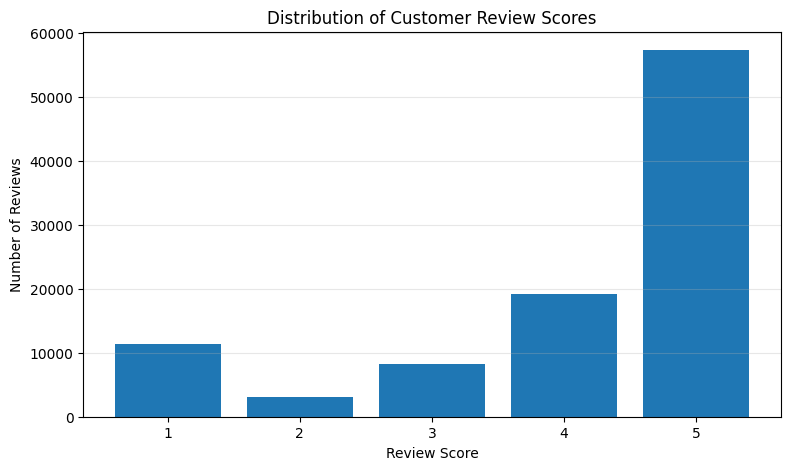

In [285]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    review_score_distribution["review_score"],
    review_score_distribution["total_reviews"]
)

plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(axis="y", alpha=0.3)

plt.show()

In [287]:
reviews_df["sentiment"] = np.select(
    [
        reviews_df["review_score"] >= 4,
        reviews_df["review_score"] == 3,
        reviews_df["review_score"] <= 2
    ],
    [
        "Positive",
        "Neutral",
        "Negative"
    ],
    default="Unknown"
)

sentiment_summary = (
    reviews_df.groupby("sentiment")
    .size()
    .reset_index(name="total_reviews")
)

sentiment_summary["percentage"] = (
    sentiment_summary["total_reviews"] / len(reviews_df)
) * 100

sentiment_summary = sentiment_summary.sort_values(
    "total_reviews", ascending=False
)

display(sentiment_summary)

,sentiment,total_reviews,percentage
2,Positive,76470,77.068048
0,Negative,14575,14.688987
1,Neutral,8179,8.242965


In [288]:
#merge reviews with orders
review_order_data = reviews_df.merge(
    processed["orders"][["order_id", "order_status"]],
    on="order_id",
    how="left"
)

#merge with order items
review_product_data = review_order_data.merge(
    processed["order_items"][["order_id", "product_id"]],
    on="order_id",
    how="inner"
)

#merge with product categories
review_product_data = review_product_data.merge(
    processed["products"][
        ["product_id", "product_category_name_english"]
    ],
    on="product_id",
    how="left"
)

#handle missing product categories
review_product_data["product_category_name_english"] = (
    review_product_data["product_category_name_english"]
    .fillna("Unknown")
)

print("Review-product records:", len(review_product_data))
print(
    "Unique orders:",
    review_product_data["order_id"].nunique()
)

Review-product records: 112372
Unique orders: 97917


In [289]:
category_satisfaction = (
    review_product_data
    .groupby("product_category_name_english")
    .agg(
        total_items=("product_id", "count"),
        total_orders=("order_id", "nunique"),
        average_review_score=("review_score", "mean")
    )
    .reset_index()
)

category_satisfaction = category_satisfaction.sort_values(
    "average_review_score",
    ascending=False
)

display(category_satisfaction.head(10))

,product_category_name_english,total_items,total_orders,average_review_score
12,cds_dvds_musicals,14,12,4.642857
30,fashion_childrens_clothes,8,8,4.500000
9,books_general_interest,549,508,4.446266
23,costruction_tools_tools,99,94,4.444444
36,flowers,31,28,4.419355
10,books_imported,60,53,4.400000
11,books_technical,266,257,4.368421
38,food_drink,279,226,4.315412
55,luggage_accessories,1088,1030,4.315257
67,small_appliances_home_oven_and_coffee,76,75,4.302632


In [290]:
display(
    category_satisfaction.sort_values(
        "average_review_score",
        ascending=True
    ).head(10)
)

,product_category_name_english,total_items,total_orders,average_review_score
64,security_and_services,2,2,2.500000
24,diapers_and_hygiene,39,27,3.256410
63,portable_kitchen_and_food_processors,15,14,3.266667
43,gaming_pc,9,8,3.333333
59,office_furniture,1687,1263,3.493183
48,home_comfort_2,27,23,3.629630
31,fashion_male_clothing,131,111,3.641221
35,fixed_telephony,262,214,3.683206
60,party_supplies,43,39,3.767442
28,fashio_female_clothing,50,39,3.780000


In [291]:
reliable_category_satisfaction = (
    category_satisfaction[
        category_satisfaction["total_items"] >= 100
    ]
    .copy()
)

print("Categories meeting minimum sample size:",
      len(reliable_category_satisfaction))

print("\nTop 10 highest-rated categories:")
display(
    reliable_category_satisfaction
    .sort_values("average_review_score", ascending=False)
    .head(10)
)

print("\nTop 10 lowest-rated categories:")
display(
    reliable_category_satisfaction
    .sort_values("average_review_score", ascending=True)
    .head(10)
)

Categories meeting minimum sample size: 53

Top 10 highest-rated categories:


,product_category_name_english,total_items,total_orders,average_review_score
9,books_general_interest,549,508,4.446266
11,books_technical,266,257,4.368421
38,food_drink,279,226,4.315412
55,luggage_accessories,1088,1030,4.315257
32,fashion_shoes,261,236,4.233716
37,food,495,445,4.218182
69,stationery,2507,2295,4.193857
62,pet_shop,1939,1701,4.185147
15,computers,200,178,4.175000
46,home_appliances,806,761,4.172457



Top 10 lowest-rated categories:


,product_category_name_english,total_items,total_orders,average_review_score
59,office_furniture,1687,1263,3.493183
31,fashion_male_clothing,131,111,3.641221
35,fixed_telephony,262,214,3.683206
5,audio,361,347,3.825485
49,home_confort,435,395,3.829885
0,Unknown,1598,1439,3.841051
20,construction_tools_safety,193,166,3.844560
8,bed_bath_table,11137,9313,3.895663
40,furniture_decor,8331,6398,3.903493
41,furniture_living_room,502,417,3.904382


In [292]:
reliable_category_satisfaction.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/reliable_category_satisfaction.csv",
    index=False
)

In [293]:
review_delivery_data = reviews_df.merge(
    delivered_orders[
        [
            "order_id",
            "delivery_difference_days",
            "delivery_status",
            "actual_delivery_days"
        ]
    ],
    on="order_id",
    how="inner"
)

print("Review-delivery records:", len(review_delivery_data))
print("Unique orders:", review_delivery_data["order_id"].nunique())

display(review_delivery_data.head())

Review-delivery records: 96361
Unique orders: 95832


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,sentiment,delivery_difference_days,delivery_status,actual_delivery_days
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59,Positive,-16.0,Early,6.133241
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13,Positive,-5.0,Early,9.452789
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24,Positive,-21.0,Early,13.314190
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06,Positive,-20.0,Early,10.644005
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53,Positive,-9.0,Early,18.232315


In [294]:
delivery_sentiment_summary = (
    review_delivery_data
    .groupby("delivery_status")
    .agg(
        total_reviews=("review_score", "count"),
        unique_orders=("order_id", "nunique"),
        average_review_score=("review_score", "mean")
    )
    .reset_index()
)

delivery_sentiment_summary["average_review_score"] = (
    delivery_sentiment_summary["average_review_score"].round(2)
)

display(
    delivery_sentiment_summary.sort_values(
        "average_review_score",
        ascending=False
    )
)

,delivery_status,total_reviews,unique_orders,average_review_score
3,Unknown,8,8,4.50
0,Early,88653,88163,4.29
2,On Time,1291,1280,4.03
1,Late,6409,6381,2.27


In [295]:
#exclude records without a valid delivery comparison
valid_review_delivery = review_delivery_data[
    review_delivery_data["delivery_difference_days"].notna()
].copy()

#correlation at review-record level
pearson_correlation = valid_review_delivery[
    ["delivery_difference_days", "review_score"]
].corr(method="pearson").iloc[0, 1]

spearman_correlation = valid_review_delivery[
    ["delivery_difference_days", "review_score"]
].corr(method="spearman").iloc[0, 1]

print("Review-record level:")
print("Pearson correlation:", round(pearson_correlation, 4))
print("Spearman correlation:", round(spearman_correlation, 4))


#aggregate multiple reviews belonging to the same order
order_level_satisfaction = (
    valid_review_delivery
    .groupby("order_id")
    .agg(
        delivery_difference_days=("delivery_difference_days", "first"),
        average_review_score=("review_score", "mean")
    )
    .reset_index()
)

order_pearson = order_level_satisfaction[
    ["delivery_difference_days", "average_review_score"]
].corr(method="pearson").iloc[0, 1]

order_spearman = order_level_satisfaction[
    ["delivery_difference_days", "average_review_score"]
].corr(method="spearman").iloc[0, 1]

print("\nOrder-level:")
print("Unique orders:", len(order_level_satisfaction))
print("Pearson correlation:", round(order_pearson, 4))
print("Spearman correlation:", round(order_spearman, 4))

Review-record level:
Pearson correlation: -0.267
Spearman correlation: -0.1762

Order-level:
Unique orders: 95824
Pearson correlation: -0.2673
Spearman correlation: -0.1762


In [296]:
#export review score distribution
review_score_distribution.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/review_score_distribution.csv",
    index=False
)

#export sentiment summary
sentiment_summary.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/review_sentiment_summary.csv",
    index=False
)

#export category satisfaction
category_satisfaction.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/category_satisfaction.csv",
    index=False
)

#export filtered category satisfaction
reliable_category_satisfaction.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/reliable_category_satisfaction.csv",
    index=False
)

#export delivery and satisfaction comparison
delivery_sentiment_summary.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/delivery_sentiment_summary.csv",
    index=False
)

#export order level correlation dataset
order_level_satisfaction.to_csv(
    "/content/drive/MyDrive/Data Analytics Portfolio/01_Olist_Ecommerce_Analytics/data/processed/order_level_satisfaction.csv",
    index=False
)

print("Customer satisfaction analysis exported successfully.")

Customer satisfaction analysis exported successfully.
